# zf1 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830, SR860
from qcodes.instrument_drivers.Keithley import Keithley2400
from qcodes.instrument_drivers.american_magnetics import AMIModel430

import sweep

from hera.analysis import GateCalibration, field_invB

from sharpelab_nb.constants import TOPLOADER
from sharpelab_nb.thermometry import temperature_from_logfile
from sharpelab_nb.drivers import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\toploader\\measurements\\aaron\\20260623-zf1'

# Connect Instruments

## Magnet

In [3]:
MAGNET_ADDR = "TCPIP0::192.168.0.101::7180::SOCKET"  # <-- verify address
magnet = AMIModel430("magnet", address=MAGNET_ADDR)
# Field in Tesla; magnet.field() is the MEASURED readback (coil constant
# 0.116783 T/A is configured on the unit). magnet.field(target) BLOCKS until
# the supply reports holding; a kernel interrupt does NOT stop the ramp.
magnet.field()

Connected to: AMERICAN MAGNETICS INC. 430 (serial:430-11-044, firmware:2.65) in 0.52s


1.104e-06

## Thermometry (file-based) + sample heater

Kernel temperature reads are **file-based**, not GPIB — the AVS bridge workers
own the bridges and write the logfiles. `temperature` is the loaded probe's
mixing chamber; the logfile path is **probe-dependent** (Probe1 = straight,
Probe2 = rotator). The sample heater is an **open-loop** Keithley voltage
source — set `heater.volt`, settle, then read T back from `temperature()`.

In [4]:
# Probe MC (sample T) — point at the LOADED probe (Probe1 straight / Probe2 rotator)
temperature = temperature_from_logfile(
    "T", r"C:\Users\toploader\temperature_logs\Probe2_MixingCh_low.txt")  # <-- verify probe
fridge_temperature = temperature_from_logfile("T_fridge", TOPLOADER.temp_logfiles["T_fridge"])
mag_temperature = temperature_from_logfile("T_magnet", TOPLOADER.temp_logfiles["T_magnet"])
print("probe MC:", temperature(), "K")

# Sample-stage heater — open-loop voltage drive (V->T is per-cooldown; device card)
heater = Keithley2400("heater", "GPIB4::12::INSTR")  # <-- verify address
heater.mode.set("VOLT")
heater.volt.step = 0.005

probe MC: 0.0337 K
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1299232, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.11s


## Lock-ins

In [5]:
sr830_1 = SR830("sr830_1", "GPIB0::8::INSTR")  # <-- verify — current channel (Ithaco 1211 preamp output)
sr830_2 = SR830("sr830_2", "GPIB0::9::INSTR")  # <-- verify
sr830_3 = SR830("sr830_3", "GPIB0::4::INSTR")  # <-- verify
sr830_4 = SR830("sr830_4", "GPIB0::1::INSTR")  # <-- verify
sr830_5 = SR830("sr830_5", "GPIB0::5::INSTR")  # <-- verify
sr830_6 = SR830("sr830_6", "GPIB0::6::INSTR")  # <-- verify
sr830_7 = SR830("sr830_7", "GPIB0::7::INSTR")  # <-- verify
# sr830_8 = SR860("sr830_8", "TCPIP::192.168.0.107::inst0::INSTR")  # <-- verify — SR860; enable if used

C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n45469, firmware:ver1.07) in 0.13s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45595, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45471, firmware:ver1.07) in 0.09s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_5 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n43722, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45470, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n43721, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41621, firmware:ver1.07) in 0.09s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_6 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_7 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_7 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys (gates)

In [6]:
# Gate Keithleys are role-named on this rig (k_tg/k_bg drive top/back gates),
# so recipes' k_tg / k_bg resolve directly. The third Keithley's role is
# per-insert (Si gate, or a probe-specific winding). Defaults: rangev 21,
# rangei 1uA, compliance 10 nA / 20 V, step 5 mV.
def _setup_k2400(k):
    # k.mode.set("VOLT")
    # k.rangev.set(21)
    # k.rangei.set(1e-6)
    # k.compliancev.set(20)
    # k.compliancei.set(1e-6)
    k.volt.step = 0.005
    return k

k_tg  = _setup_k2400(Keithley2400("k_tg",  "GPIB4::9::INSTR"))   # <-- verify — top gate
k_bg  = _setup_k2400(Keithley2400("k_bg",  "GPIB4::10::INSTR"))  # <-- verify — back gate
k_tg2 = _setup_k2400(Keithley2400("k_tg2", "GPIB4::11::INSTR"))  # <-- verify — third Keithley (per-insert role)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028439, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028442, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028489, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s


## DC205 (DC current bias)

On the toploader, gates are Keithleys; the DC205s are **DC current-bias**
sources (through a 100 MΩ series resistor — see the device card). Set
`volt -> 0` before reconfiguring or ending a measurement.

In [7]:
dc205_1 = SRS_DC205("dc205_1", "ASRL6::INSTR")  # <-- verify address — DC current bias
dc205_1.volt = dc205_1.voltage
dc205_1.volt.step = 0.005

dc205_3 = SRS_DC205("dc205_3", "ASRL7::INSTR")  # <-- verify address — second DC205
dc205_3.volt = dc205_3.voltage
dc205_3.volt.step = 0.005

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500516, firmware:ver1.80) in 0.03s
Connected to: Stanford_Research_Systems DC205 (serial:s/n20500513, firmware:ver1.80) in 0.03s


# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [8]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`.
TG_MIN, TG_MAX = -7.0, +6.0   # top gate (k_tg), V    # <-- validate
BG_MIN, BG_MAX = -4.0, +4.2   # back gate (k_bg), V    # <-- validate
k_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter, so
# this validator rejects magnet.field(target) with |B| > cap before any
# hardware traffic. Driver backstop: |B| <= COIL? x current_limit (~9 T) on the
# AMI430 unit.
B_SESSION_CAP = 0.1  # Tesla (100 mT)    # <-- validate (session cap from brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Sample-heater ceiling for sustained runs (V, not T — open-loop drive).
HEATER_V_MAX = 6.5  # V    # <-- validate
heater.volt.vals = validators.Numbers(0, HEATER_V_MAX)

# DC current-bias range (SRS DC205 hardware: +/-15 V -> +/-150 nA at 100 MOhm).
dc205_1.volt.vals = validators.Numbers(-15, 15)

# Helpers

In [9]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [10]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [11]:
# slot: meas-config — channel/contact assignments + gains from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Toploader contacts are wired
# DIRECT (no QSwitch) — name the contact pair per channel. Always set 'comment'
# per run — structured, current, no inherited text.
meas_config = {
    "sr1": "5-4",     "sr1_gain": -1e6,   # current channel (Ithaco 1211)    # <-- validate
    "sr2": "5-4",     "sr2_gain": 1e2,    # 2T voltage (preamp x100)    # <-- validate
    "sr3": "30-31",   "sr3_gain": 1e2,    # 4T longitudinal (preamp x100)    # <-- validate
    "bias_resistor": 1e8,
    "bias_voltage_1": sr830_1.amplitude(),
    "lockin_freq_1": sr830_1.frequency(),
    "comment": "<SET PER RUN>",
}

# HERA — zf1 session start (2026-06-23)

## HERA — Gate C: contact-wiring liveness (first-session, no references)

**Bring-up status.** Gate A green — setup cells ran sequentially in this kernel (magnet 1.1 µT ≈ 0, probe MC 33.7 mK base, all lock-ins / gates / DC205 connected). Gate B green — SAFETIES (cell 16) committed TG (−7, +6), BG (−4, +4.2), B-cap 0.1 T, heater 6.5 V: exact device-card / brief numbers, all inside machine limits (0.1 T ≪ 9 T). Remaining gate is **C**: confirm the provided wiring is alive before the Step-1 map.

**What this is.** `gate-current-sanity-check`, **cheap-liveness branch only** — validators are already committed from the device card, so the validator-blessing loop / range-finding (blocklisted this session) is *not* run. One parametrized leg per run: sweep one gate 0 → ±2 V (well inside validators), park the other at 0; `nplci=10` on both gate-current channels for pA readback; AC drive set to **1 nA** (sr830_1.amplitude 0.1 V through 100 MΩ). Magnet is **not** touched — Step 1 needs pristine field.

**What to read on the live Qt plot** (E0 — you have the screen):
- **sr3** (4T R_xx, contacts 30-31) `X` nonzero and smoothly varying → device alive + 4T wiring good.
- both gate `*.curr` flat in **pA** to the endpoint → gates clean, no leakage; parked gate at the readback floor → no cross-gate path.
- If sr3 `X` rails or is buried in noise, bump that lock-in's sensitivity and re-run (we have no R-scale prior — first session).

**Run the four legs** by editing the EDIT block: `k_bg 0→+2`, `k_bg 0→−2`, `k_tg 0→+2`, `k_tg 0→−2`. ~1.5–2 min/leg. Tell me what you see (sr3 X alive? gate currents pA? rough R_xx scale?) and I'll advance to the **Step-1 pristine-field (n, D) gate map** — taken before energising the magnet, doing double duty for the cap-ratio (CNP-slope) calibration the device card flags as an unverified prior.


probe MC T : 0.0337 K     (expect base, mK)
magnet B   : -1.082e-05 T   (expect ~0, NOT energised)
k_tg.volt  : 0.0 V      (expect 0)
k_bg.volt  : 0.0 V      (expect 0)
2026-06-23 15:22:56,035 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-23 15:22:56,548 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-23 15:22:56,559 [INFO] Starting sweep with ID 0
2026-06-23 15:22:56,560 [INFO] Minimum duration 0h 0m 51s


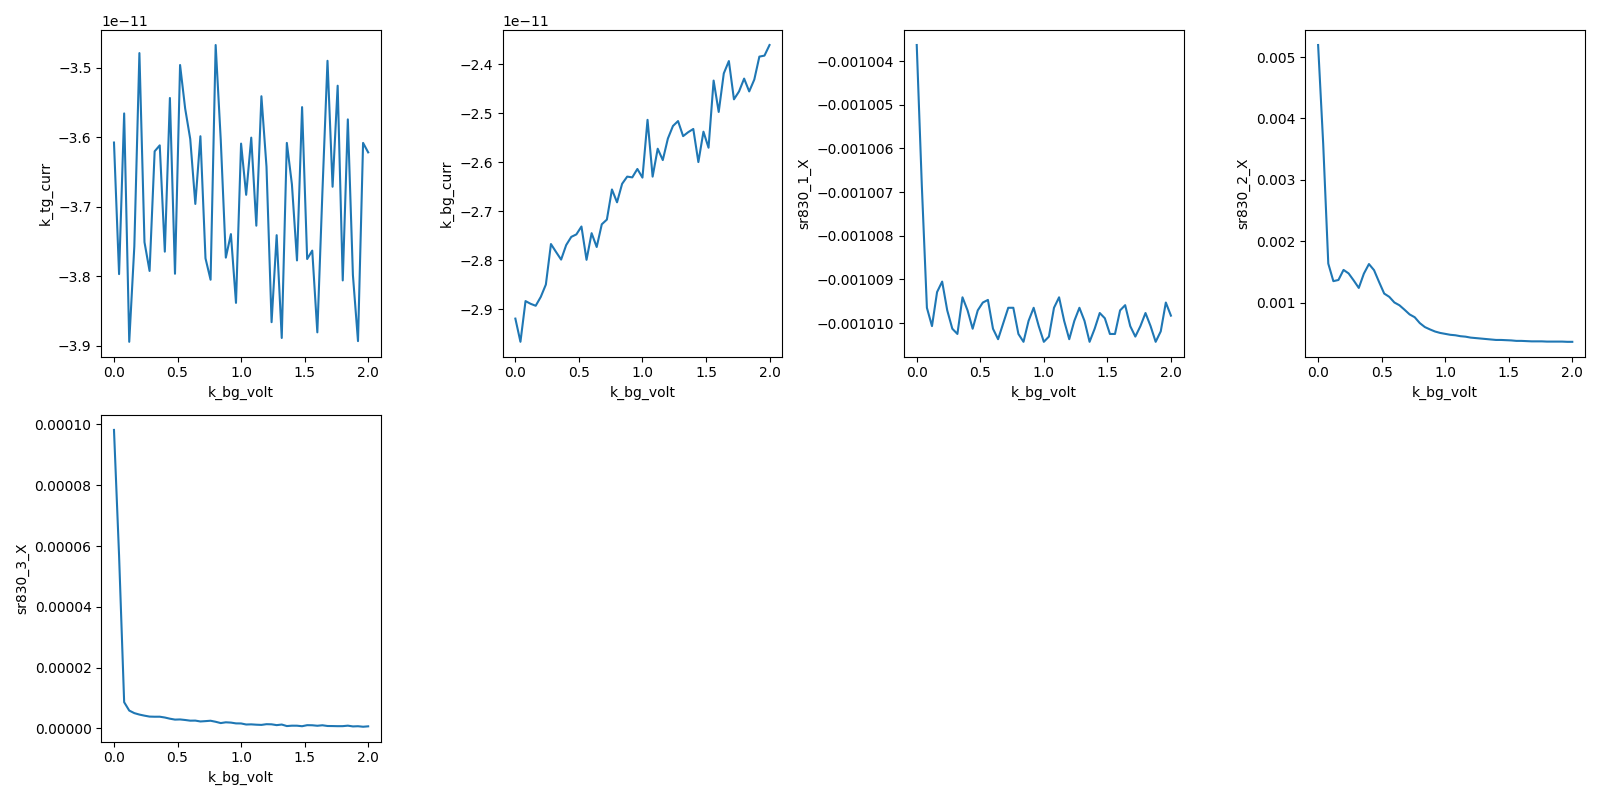

2026-06-23 15:24:43,568 [INFO] Completed in 0h 1m 46s
2026-06-23 15:24:43,568 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\0\data.tsv.gz
2026-06-23 15:24:44,080 [INFO] Ramping k_bg_volt: 2.0 -> 0


In [12]:
# === Gate C — cheap contact-wiring liveness (gate-current-sanity-check, liveness branch) ===
# Edit this block per leg; run BG+, BG-, TG+, TG- (the other gate parked at 0).
gate       = k_bg          # k_tg | k_bg
v_endpoint = +2.0          # modest endpoint, INSIDE committed validators
n_pts      = 51
delay      = 1             # s
lockins    = [sr830_1, sr830_2, sr830_3]   # mc active set: current, 2T, 4T
# ============================================================================

# --- silent-precondition reads (expected vs actual) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T : {_T:.4f} K     (expect base, mK)")
print(f"magnet B   : {_B:.3e} T   (expect ~0, NOT energised)")
print(f"k_tg.volt  : {k_tg.volt()} V      (expect 0)")
print(f"k_bg.volt  : {k_bg.volt()} V      (expect 0)")
assert _T < 0.1, "probe not at base — investigate before sweeping"
assert abs(_B) < 5e-3, "magnet not near zero — Step 1 needs pristine field"

# pA-floor gate-current readback (no Cell-B: validators already committed from card)
k_tg.nplci(10)
k_bg.nplci(10)

# AC sense drive -> ~1 nA at the device (0.1 V through 100 MOhm; device card)
sr830_1.amplitude(0.1)

meas_config["comment"] = f"gate C liveness: {gate.name} 0 -> {v_endpoint:+g} V"
s = sweep.AsyncStation(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment(f'leg: {gate.name} 0 -> {v_endpoint:+g} V (liveness)')

# park non-swept gate at 0
s.ramp(k_bg.volt, 0)
s.ramp(k_tg.volt, 0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in lockins:
    s.fp(lia.X).fp(lia.P)

xp = gate.volt
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for lia in lockins:
    s.plot(xp, lia.X)

try:
    s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
finally:
    s.ramp(gate.volt, 0)


### HERA — Gate C, remaining liveness legs (BG−, TG+, TG−)

Leg 1 (BG+, cell 25) was clean: device passes 1.01 nA, sr3 4T R_xx live and gate-responsive (982→7 Ω), both gate currents in pA (k_bg 30 pA / k_tg 39 pA), T = 34 mK. The three cells below are the remaining legs, pre-filled (one cell per leg for a clean append-only history) — run each in order; same live-plot read (sr3 X alive + smoothly varying, both `*.curr` flat in pA). The negative legs are the ones that matter for the arc: the proximity-SC region sits at **D < 0**, so we'll work in negative-gate territory downstream. ~1.5–2 min/leg.


probe MC T : 0.0337 K     (expect base, mK)
magnet B   : -3.091e-06 T   (expect ~0, NOT energised)
k_tg.volt  : 0.0 V      (expect 0)
k_bg.volt  : 0.0 V      (expect 0)
2026-06-23 15:29:13,612 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-23 15:29:14,124 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-23 15:29:14,133 [INFO] Starting sweep with ID 1
2026-06-23 15:29:14,134 [INFO] Minimum duration 0h 0m 51s


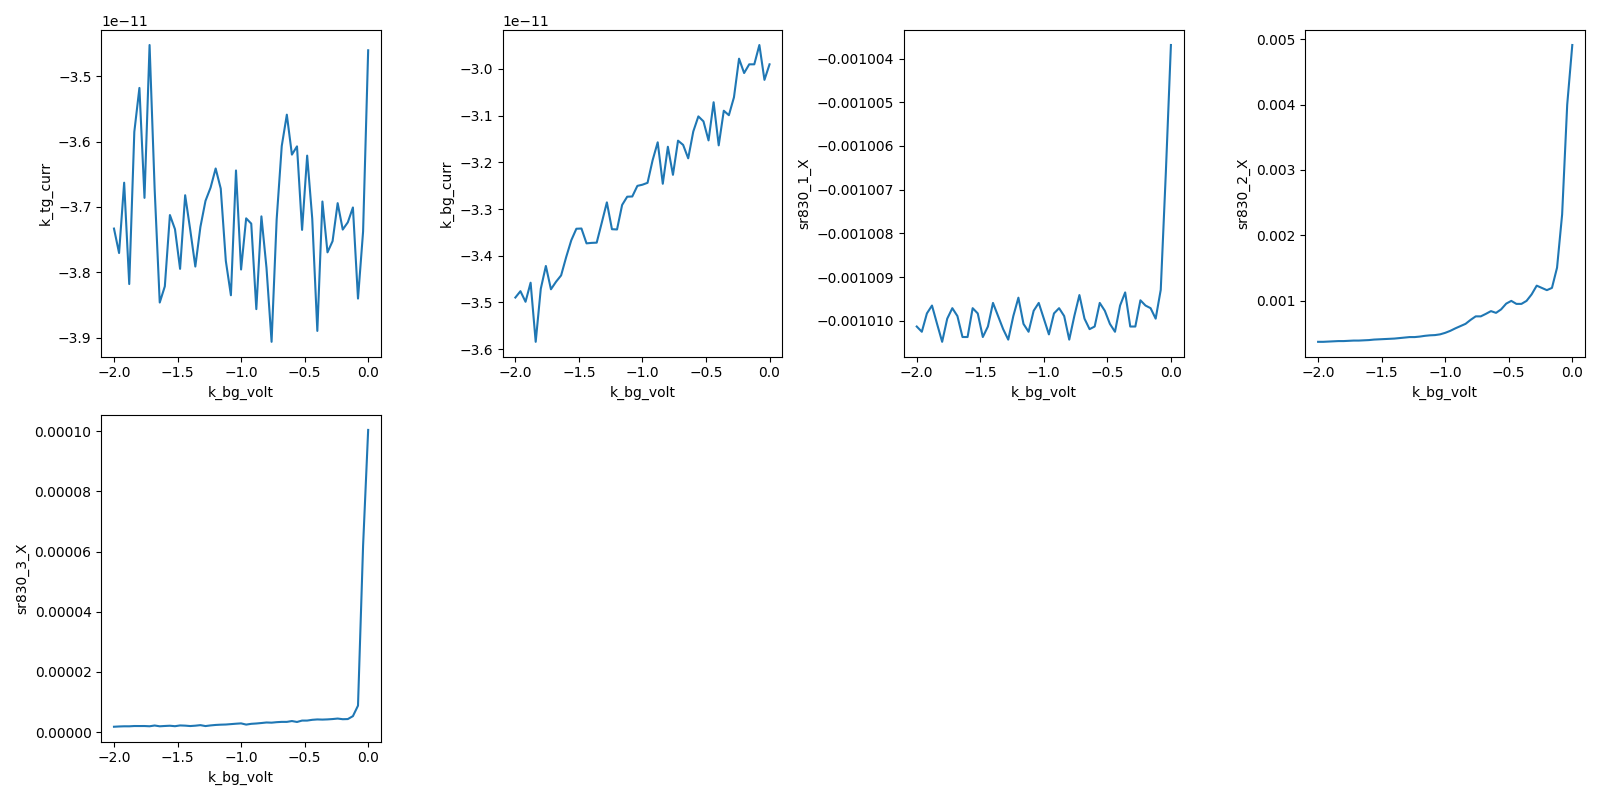

2026-06-23 15:31:01,299 [INFO] Completed in 0h 1m 46s
2026-06-23 15:31:01,300 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\1\data.tsv.gz
2026-06-23 15:31:01,817 [INFO] Ramping k_bg_volt: -2.0 -> 0


In [13]:
# === Gate C liveness leg — k_bg 0 -> -2.0 V (gate-current-sanity-check) ===
gate       = k_bg
v_endpoint = -2.0          # INSIDE committed validators
n_pts      = 51
delay      = 1
lockins    = [sr830_1, sr830_2, sr830_3]
# ============================================================================

# --- silent-precondition reads (expected vs actual) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T : {_T:.4f} K     (expect base, mK)")
print(f"magnet B   : {_B:.3e} T   (expect ~0, NOT energised)")
print(f"k_tg.volt  : {k_tg.volt()} V      (expect 0)")
print(f"k_bg.volt  : {k_bg.volt()} V      (expect 0)")
assert _T < 0.1, "probe not at base — investigate before sweeping"
assert abs(_B) < 5e-3, "magnet not near zero — Step 1 needs pristine field"

# pA-floor gate-current readback
k_tg.nplci(10)
k_bg.nplci(10)

# AC sense drive -> ~1 nA at the device
sr830_1.amplitude(0.1)

meas_config["comment"] = f"gate C liveness: {gate.name} 0 -> {v_endpoint:+g} V"
s = sweep.AsyncStation(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment(f'leg: {gate.name} 0 -> {v_endpoint:+g} V (liveness)')

# park non-swept gate at 0
s.ramp(k_bg.volt, 0)
s.ramp(k_tg.volt, 0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in lockins:
    s.fp(lia.X).fp(lia.P)

xp = gate.volt
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for lia in lockins:
    s.plot(xp, lia.X)

try:
    s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
finally:
    s.ramp(gate.volt, 0)


probe MC T : 0.0337 K     (expect base, mK)
magnet B   : 5.520e-06 T   (expect ~0, NOT energised)
k_tg.volt  : 0.0 V      (expect 0)
k_bg.volt  : 0.0 V      (expect 0)
2026-06-23 15:31:06,368 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-23 15:31:06,881 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-23 15:31:06,891 [INFO] Starting sweep with ID 2
2026-06-23 15:31:06,892 [INFO] Minimum duration 0h 0m 51s


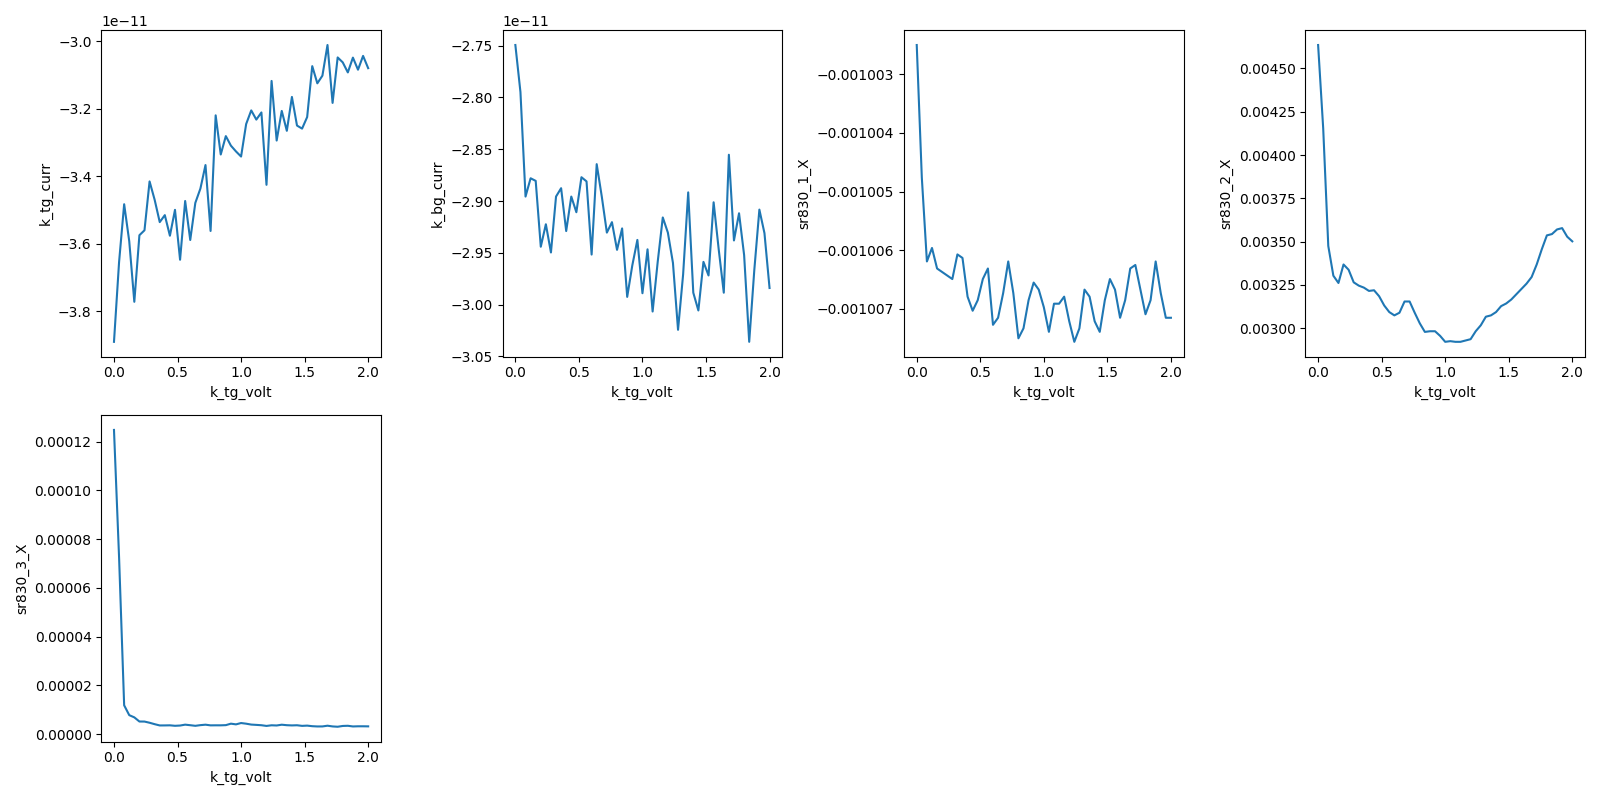

2026-06-23 15:32:53,662 [INFO] Completed in 0h 1m 46s
2026-06-23 15:32:53,662 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\2\data.tsv.gz
2026-06-23 15:32:54,178 [INFO] Ramping k_tg_volt: 2.0 -> 0


In [14]:
# === Gate C liveness leg — k_tg 0 -> +2.0 V (gate-current-sanity-check) ===
gate       = k_tg
v_endpoint = +2.0          # INSIDE committed validators
n_pts      = 51
delay      = 1
lockins    = [sr830_1, sr830_2, sr830_3]
# ============================================================================

# --- silent-precondition reads (expected vs actual) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T : {_T:.4f} K     (expect base, mK)")
print(f"magnet B   : {_B:.3e} T   (expect ~0, NOT energised)")
print(f"k_tg.volt  : {k_tg.volt()} V      (expect 0)")
print(f"k_bg.volt  : {k_bg.volt()} V      (expect 0)")
assert _T < 0.1, "probe not at base — investigate before sweeping"
assert abs(_B) < 5e-3, "magnet not near zero — Step 1 needs pristine field"

# pA-floor gate-current readback
k_tg.nplci(10)
k_bg.nplci(10)

# AC sense drive -> ~1 nA at the device
sr830_1.amplitude(0.1)

meas_config["comment"] = f"gate C liveness: {gate.name} 0 -> {v_endpoint:+g} V"
s = sweep.AsyncStation(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment(f'leg: {gate.name} 0 -> {v_endpoint:+g} V (liveness)')

# park non-swept gate at 0
s.ramp(k_bg.volt, 0)
s.ramp(k_tg.volt, 0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in lockins:
    s.fp(lia.X).fp(lia.P)

xp = gate.volt
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for lia in lockins:
    s.plot(xp, lia.X)

try:
    s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
finally:
    s.ramp(gate.volt, 0)


probe MC T : 0.0337 K     (expect base, mK)
magnet B   : -1.325e-06 T   (expect ~0, NOT energised)
k_tg.volt  : 0.0 V      (expect 0)
k_bg.volt  : 0.0 V      (expect 0)
2026-06-23 15:32:58,779 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-23 15:32:59,291 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-23 15:32:59,309 [INFO] Starting sweep with ID 3
2026-06-23 15:32:59,310 [INFO] Minimum duration 0h 0m 51s


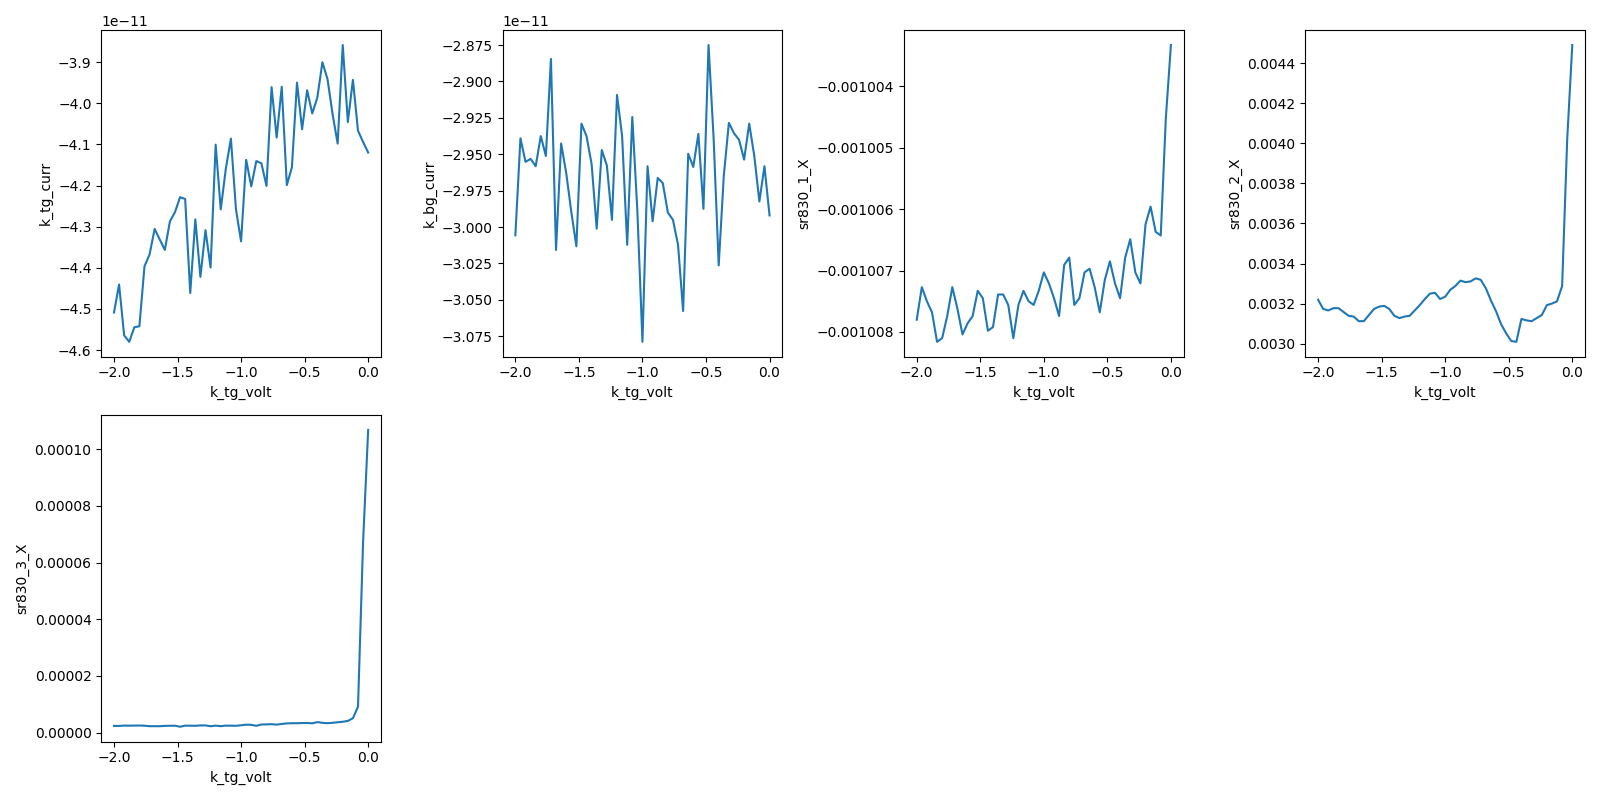

2026-06-23 15:34:46,185 [INFO] Completed in 0h 1m 46s
2026-06-23 15:34:46,186 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\3\data.tsv.gz
2026-06-23 15:34:46,697 [INFO] Ramping k_tg_volt: -2.0 -> 0


In [15]:
# === Gate C liveness leg — k_tg 0 -> -2.0 V (gate-current-sanity-check) ===
gate       = k_tg
v_endpoint = -2.0          # INSIDE committed validators
n_pts      = 51
delay      = 1
lockins    = [sr830_1, sr830_2, sr830_3]
# ============================================================================

# --- silent-precondition reads (expected vs actual) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T : {_T:.4f} K     (expect base, mK)")
print(f"magnet B   : {_B:.3e} T   (expect ~0, NOT energised)")
print(f"k_tg.volt  : {k_tg.volt()} V      (expect 0)")
print(f"k_bg.volt  : {k_bg.volt()} V      (expect 0)")
assert _T < 0.1, "probe not at base — investigate before sweeping"
assert abs(_B) < 5e-3, "magnet not near zero — Step 1 needs pristine field"

# pA-floor gate-current readback
k_tg.nplci(10)
k_bg.nplci(10)

# AC sense drive -> ~1 nA at the device
sr830_1.amplitude(0.1)

meas_config["comment"] = f"gate C liveness: {gate.name} 0 -> {v_endpoint:+g} V"
s = sweep.AsyncStation(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment(f'leg: {gate.name} 0 -> {v_endpoint:+g} V (liveness)')

# park non-swept gate at 0
s.ramp(k_bg.volt, 0)
s.ramp(k_tg.volt, 0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in lockins:
    s.fp(lia.X).fp(lia.P)

xp = gate.volt
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for lia in lockins:
    s.plot(xp, lia.X)

try:
    s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
finally:
    s.ramp(gate.volt, 0)


## HERA — Step 1: pristine-field gate map (coarse reconnaissance + cap-ratio)

**Bring-up done** — Gate C green (4 legs, all clean: device passes 1.01 nA, sr3 4T R_xx live, gate currents tens-of-pA both gates/polarities). This is the first science cell.

**What / why** (`gatemap`, investigation `sc-characterization.md` Step 1). An **axis-aligned raw (V_tg, V_bg)** megasweep at **pristine field** — taken *before the magnet is energised*, because any remanence (~10 mT on this rig once energised) can erase a fragile SC. Double duty: the CNP ridge slope gives the cap ratio `c_bg/c_tg` (`cnp-and-dline-calibration`), which the device card flags as an unverified prior (geometry → 1.18). All downstream (n, D) coordinates depend on pinning it. This is a **coarse reconnaissance**: it locates the CNP + the broad metallic/insulating landscape to aim the next step; it is *not* expected to resolve the narrow candidate SC arc (~5×10¹⁰ cm⁻²) — linecuts do that.

**Geometry.** 41 (TG slow) × 61 (BG fast) = 2501 pts. TG ∈ [−6.8, +5.8], BG ∈ [−3.8, +4.0] — full validator envelope inset 0.2 V. slow_delay=3, fast_delay=1 (fast_delay=1 validated by the legs' clean smooth data). Starts at the negative co-polarized (cool) corner; the **first fast row sweeps BG to +4.0, crossing the maximum-|ΔV| (10.8 V) opposed corner** — the leakage stress test happens in the first minutes.

**Leakage protection.** Limits are isaac's known-safe operating envelope (range-finding blocklisted = already established), and I leave the proven Keithley config untouched. Both gate currents are fp'd and live-plotted — **if either gate current departs its pA baseline (turns up off the flat charging level), interrupt.** This is the abort path; no software guard (the leakage-survey `LeakageDetector` is DRAFT/beta — not deploying it on a long run).

**Checkpoints** (I'm arming a background monitor):
- **First row (~3 min):** (1) both gate currents stay pA across the opposed corner; (2) sr2/sr3 X not railing at the CNP nor buried in noise in the metallic regions — if either, interrupt and I'll reset sensitivity; (3) data smooth = settled.
- **~Every 30 min:** CNP ridge forming with a sane slope (~−1.2 expected); landscape taking shape.

**Cost** ~1.8–2 h (per-point ~2.3 s incl. 5 mV-step gate ramps; +~10 min row ramp-backs, megasweep doesn't serpentine). **Coverage note:** this covers the full (n, D) envelope at *coarse* resolution — the eventual not-SC coverage gate and candidate confirmation need the finer follow-ups. Run when ready; I'll read first-row leakage/sensitivity off disk and call continue/adjust.


In [ ]:
# === Step 1 — pristine-field gate map (gatemap): coarse reconnaissance + cap-ratio ===
# Axis-aligned raw (V_tg, V_bg); MAGNET UNTOUCHED (pristine field). TG slow / BG fast.

# --- silent-precondition reads (expected vs actual) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T : {_T:.4f} K       (expect base, mK)")
print(f"magnet B   : {_B:.3e} T     (expect ~0 — NOT energised; pristine field)")
print(f"k_tg.volt  : {k_tg.volt()} V        (expect 0)")
print(f"k_bg.volt  : {k_bg.volt()} V        (expect 0)")
assert _T < 0.1, "probe not at base — investigate before a 2 h map"
assert abs(_B) < 5e-3, "magnet not near zero — Step 1 REQUIRES pristine field; do not energise"

# Standard gate-current integration for the map (legs left nplci at 10).
k_tg.nplci(1)
k_bg.nplci(1)

# AC sense drive -> ~1 nA at the device (0.1 V through 100 MOhm; device card).
sr830_1.amplitude(0.1)

# Map extent: full validator envelope inset 0.2 V. TG (-7,+6); BG (-4,+4.2).
V_tg = np.linspace(-6.8, 5.8, 41)   # slow (larger span -> slow to avoid big fast ramp-backs)
V_bg = np.linspace(-3.8, 4.0, 61)   # fast (smaller span; 0.13 V/pt resolves the CNP)

meas_config["comment"] = "Step1 pristine-field gatemap 41x61, TG[-6.8,5.8] BG[-3.8,4.0], B=0 (not energised), cap-ratio + reconnaissance"
s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('Step 1 pristine-field reconnaissance + cap-ratio (cnp-and-dline-calibration)')
s.add_comment(f'TG slow [{V_tg[0]:+g},{V_tg[-1]:+g}] x{len(V_tg)}; BG fast [{V_bg[0]:+g},{V_bg[-1]:+g}] x{len(V_bg)}; B=0')

# Move to the start corner (negative, co-polarized -> cool) and settle.
s.ramp(k_tg.volt, V_tg[0])
s.ramp(k_bg.volt, V_bg[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

# Live leakage watch (interrupt if a gate current leaves its pA baseline) + signal.
s.plot(k_bg.volt, k_bg.curr)
s.plot(k_bg.volt, k_tg.curr)
for lia in (sr830_2, sr830_3):
    s.plot(k_bg.volt, lia.X)

try:
    s.megasweep(
        k_tg.volt, V_tg,
        k_bg.volt, V_bg,
        slow_delay=3, fast_delay=1,
    )
finally:
    s.ramp(k_bg.volt, 0)
    s.ramp(k_tg.volt, 0)


## HERA — Step 1 map (CORRECTED extent) — run this, NOT cell 33

Supersedes cell 33: that cell inset the box 0.2 V for no good reason. The validators are isaac's known-safe operating envelope, so the map uses the **full range**: **TG [−7, +6], BG [−4, +4.2]**. Everything else unchanged — 41 (TG slow) × 61 (BG fast), axis-aligned raw gate voltages, **magnet untouched** (pristine field), double duty for the cap-ratio (CNP slope). Start at the negative co-polarized corner; first fast row sweeps BG to +4.2 across the full opposed corner (|ΔV| = 11.2 V) — leakage stress test in the first minutes; watch both gate currents stay pA, sr2/sr3 X not railing/buried. ~1.8–2 h. Monitor is armed; I'll first-row-check off disk.


probe MC T : 0.0337 K       (expect base, mK)
magnet B   : -2.870e-06 T     (expect ~0 — NOT energised; pristine field)
k_tg.volt  : 0.0 V        (expect 0)
k_bg.volt  : 0.0 V        (expect 0)
2026-06-23 15:45:54,289 [INFO] Ramping k_tg_volt: 0.0 -> -7.0
2026-06-23 15:46:03,278 [INFO] Ramping k_bg_volt: 0.0 -> -4.0
2026-06-23 15:46:18,377 [INFO] Starting megasweep with ID 4
2026-06-23 15:46:18,378 [INFO] Minimum duration 0h 43m 44s


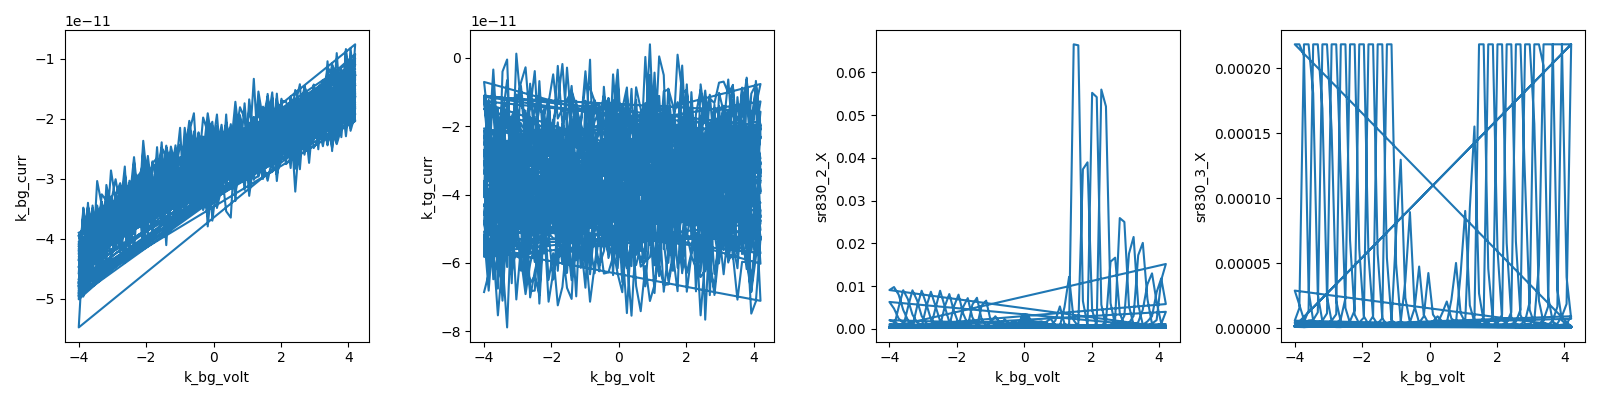

2026-06-23 16:50:24,431 [INFO] Completed in 1h 4m 5s
2026-06-23 16:50:24,432 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\4\data.tsv.gz
2026-06-23 16:50:24,496 [INFO] Ramping k_bg_volt: 4.2 -> 0
2026-06-23 16:50:29,828 [INFO] Ramping k_tg_volt: 6.0 -> 0


In [16]:
# === Step 1 — pristine-field gate map (gatemap): coarse reconnaissance + cap-ratio ===
# CORRECTED EXTENT — full validators TG(-7,+6) BG(-4,+4.2). Supersedes cell 33.
# Axis-aligned raw (V_tg, V_bg); MAGNET UNTOUCHED (pristine field). TG slow / BG fast.

# --- silent-precondition reads (expected vs actual) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T : {_T:.4f} K       (expect base, mK)")
print(f"magnet B   : {_B:.3e} T     (expect ~0 — NOT energised; pristine field)")
print(f"k_tg.volt  : {k_tg.volt()} V        (expect 0)")
print(f"k_bg.volt  : {k_bg.volt()} V        (expect 0)")
assert _T < 0.1, "probe not at base — investigate before a 2 h map"
assert abs(_B) < 5e-3, "magnet not near zero — Step 1 REQUIRES pristine field; do not energise"

# Standard gate-current integration for the map (legs left nplci at 10).
k_tg.nplci(1)
k_bg.nplci(1)

# AC sense drive -> ~1 nA at the device (0.1 V through 100 MOhm; device card).
sr830_1.amplitude(0.1)

# Map extent: FULL validator envelope. TG (-7,+6); BG (-4,+4.2).
V_tg = np.linspace(-7.0, 6.0, 41)   # slow (larger span -> slow to avoid big fast ramp-backs)
V_bg = np.linspace(-4.0, 4.2, 61)   # fast (smaller span; ~0.137 V/pt resolves the CNP)

meas_config["comment"] = "Step1 pristine-field gatemap 41x61, TG[-7,6] BG[-4,4.2], B=0 (not energised), cap-ratio + reconnaissance"
s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('Step 1 pristine-field reconnaissance + cap-ratio (cnp-and-dline-calibration)')
s.add_comment(f'TG slow [{V_tg[0]:+g},{V_tg[-1]:+g}] x{len(V_tg)}; BG fast [{V_bg[0]:+g},{V_bg[-1]:+g}] x{len(V_bg)}; B=0')

# Move to the start corner (negative, co-polarized -> cool) and settle.
s.ramp(k_tg.volt, V_tg[0])
s.ramp(k_bg.volt, V_bg[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

# Live leakage watch (interrupt if a gate current leaves its pA baseline) + signal.
s.plot(k_bg.volt, k_bg.curr)
s.plot(k_bg.volt, k_tg.curr)
for lia in (sr830_2, sr830_3):
    s.plot(k_bg.volt, lia.X)

try:
    s.megasweep(
        k_tg.volt, V_tg,
        k_bg.volt, V_bg,
        slow_delay=3, fast_delay=1,
    )
finally:
    s.ramp(k_bg.volt, 0)
    s.ramp(k_tg.volt, 0)


## HERA — Step 1→2: constant-D n-linecuts (locate the SC candidate arc)

Run 4 confirmed the cap ratio (c_bg/c_tg = 1.19) and the landscape, but **cannot resolve SC** — at coarse 1 nA the hole-side R is floor/railing-limited. Per `sc-characterization.md` Step 1 ("locate with linecuts first — the arc is narrow, a blind polygon steps over it"), this cell takes **three constant-D n-linecuts at the favorable sign** (D < 0 = holes into WSe₂, house convention): **D = −0.4, −0.5, −0.6 V/nm**, each scanning **n = −8 → −1 ×10¹¹ cm⁻²** (wider than the nominal −4 to −6 band) at ~1×10¹⁰ step — several points across the expected ~5×10¹⁰ arc width. Hole side only, so we avoid the n≈0 gap and keep R resolvable.

Mechanically a designed constant-D line: `calc_gate_voltages(ns, D0, c_tg, c_bg, n_offset)` → `sanitize_tg_bg` (validated off-line: all three D values land 71/71 in-range) → `multisweep`. **Magnet untouched** (still pristine — effective-zero-field comes later, only once a candidate is found). Drive kept at 1 nA (locator; SC-safe); sensitivity left as run-4 (resolves 5–500 Ω off the CNP). One cell, three runs in sequence, ~8–10 min total.

**What I'm looking for:** a relative R_xx **dip** vs n that strengthens/tracks as |D| grows — that flags the candidate (n, D) to pin with a tight map and then probe with bias spectroscopy (dV/dI), the real SC test. If nothing on D<0, I'll check the D>0 corner next. I'll read the first cut (D=−0.4) off disk as the checkpoint. Watch gate currents stay pA on your live plot.


probe MC T : 0.0337 K     (expect base, mK)
magnet B   : 1.855e-05 T   (expect ~0 — NOT energised; still pristine)
k_tg.volt  : 0.0 V  ;  k_bg.volt : 0.0 V   (expect 0)
D=-0.40 V/nm: 71/71 pts in validators  Vtg[-3.66,-3.16] Vbg[+2.21,+2.63]
2026-06-23 17:04:08,757 [INFO] Ramping k_tg_volt: 0.0 -> -3.6628522833887693
2026-06-23 17:04:13,542 [INFO] Ramping k_bg_volt: 0.0 -> 2.212347392720407
2026-06-23 17:04:21,343 [INFO] Starting multisweep with ID 5
2026-06-23 17:04:21,344 [INFO] Minimum duration 0h 1m 25s


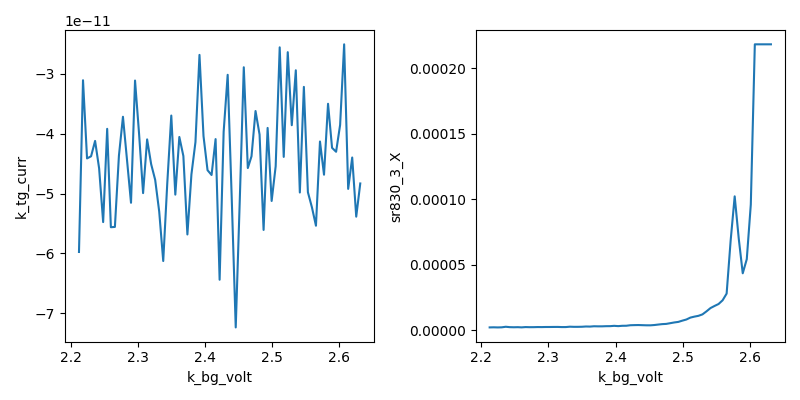

2026-06-23 17:05:58,444 [INFO] Completed in 0h 1m 36s
2026-06-23 17:05:58,445 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\5\data.tsv.gz
D=-0.50 V/nm: 71/71 pts in validators  Vtg[-4.45,-3.95] Vbg[+2.87,+3.29]
2026-06-23 17:05:58,508 [INFO] Ramping k_tg_volt: -3.1645 -> -4.4495189500554355
2026-06-23 17:06:00,213 [INFO] Ramping k_bg_volt: 2.6315 -> 2.873967802027949
2026-06-23 17:06:05,525 [INFO] Starting multisweep with ID 6
2026-06-23 17:06:05,526 [INFO] Minimum duration 0h 1m 25s


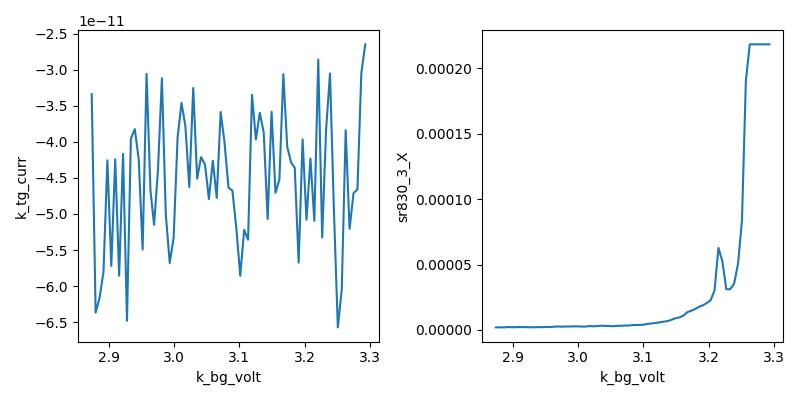

2026-06-23 17:07:42,974 [INFO] Completed in 0h 1m 37s
2026-06-23 17:07:42,975 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\6\data.tsv.gz
D=-0.60 V/nm: 71/71 pts in validators  Vtg[-5.24,-4.74] Vbg[+3.54,+3.95]
2026-06-23 17:07:43,037 [INFO] Ramping k_tg_volt: -3.9515 -> -5.2361856167221035
2026-06-23 17:07:44,737 [INFO] Ramping k_bg_volt: 3.293 -> 3.5355882113354906
2026-06-23 17:07:50,043 [INFO] Starting multisweep with ID 7
2026-06-23 17:07:50,044 [INFO] Minimum duration 0h 1m 25s


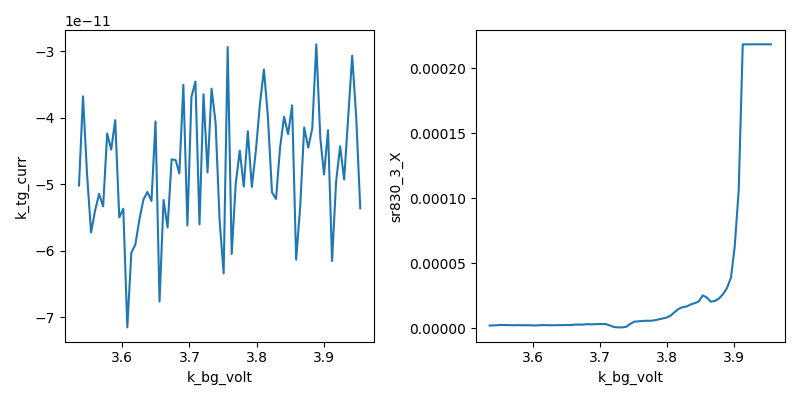

2026-06-23 17:09:26,987 [INFO] Completed in 0h 1m 36s
2026-06-23 17:09:26,988 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\7\data.tsv.gz
2026-06-23 17:09:27,050 [INFO] Ramping k_tg_volt: -4.738 -> 0
2026-06-23 17:09:33,148 [INFO] Ramping k_bg_volt: 3.9545 -> 0


In [17]:
# === Step 1->2 — constant-D n-linecuts: locate the SC candidate arc (favorable sign D<0) ===
# B=0 (magnet untouched, still pristine). One cell -> three runs (D = -0.4, -0.5, -0.6 V/nm).
from sharpelab_nb.gates import stack_capacitance, calc_gate_voltages, calc_nD

# --- silent-precondition reads (expected vs actual) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T : {_T:.4f} K     (expect base, mK)")
print(f"magnet B   : {_B:.3e} T   (expect ~0 — NOT energised; still pristine)")
print(f"k_tg.volt  : {k_tg.volt()} V  ;  k_bg.volt : {k_bg.volt()} V   (expect 0)")
assert _T < 0.1, "probe not at base — investigate"
assert abs(_B) < 5e-3, "magnet not near zero — keep pristine for the candidate locate"

# Session calibration from run-4 CNP fit: c_bg/c_tg = 1.189, CNP intercept b = +0.0895 V.
c_tg = stack_capacitance([(23.6, 3.0)])
c_bg = 1.189 * c_tg
n_offset = -calc_nD(0.0, 0.0895, c_tg, c_bg)[0]
D_offset = 0.0     # assumed (no +/-D-symmetry feature located yet)

ns = np.linspace(-0.8, -0.1, 71)   # 1e12 cm^-2  (= -8e11 .. -1e11), hole side
D_list = [-0.4, -0.5, -0.6]        # V/nm, favorable sign (holes -> WSe2)

sr830_1.amplitude(0.1)             # 1 nA AC (locator, SC-safe)
k_tg.nplci(1); k_bg.nplci(1)

for D0 in D_list:
    vtg, vbg = calc_gate_voltages(ns, D0*np.ones_like(ns), c_tg, c_bg, n_offset=n_offset, D_offset=D_offset)
    vtg, vbg = sanitize_tg_bg(vtg, vbg, tg_lims, bg_lims)
    print(f"D={D0:+.2f} V/nm: {len(vtg)}/{len(ns)} pts in validators  "
          f"Vtg[{vtg.min():+.2f},{vtg.max():+.2f}] Vbg[{vbg.min():+.2f},{vbg.max():+.2f}]")

    meas_config["comment"] = f"constant-D n-linecut D={D0:+.2f} V/nm, n[-8,-1]e11, B=0 (SC candidate locate)"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('cnp-and-dline-calibration')
    s.add_comment(f'SC-locate constant-D n-linecut: D={D0:+.2f} V/nm; n[-8,-1]e11; c_bg/c_tg=1.189; B=0')

    s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); time.sleep(5)
    s.fp(temperature)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    for lia in (sr830_1, sr830_2, sr830_3):
        s.fp(lia.X).fp(lia.P)
    s.plot(k_bg.volt, k_tg.curr)
    s.plot(k_bg.volt, sr830_3.X)
    s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=1.2)

# park gates
s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)


## HERA — Step 1 "map it tight": (n, D) zoom on the SC candidate

The D=−0.6 linecut (run 7) showed a sharp isolated R_xx dip to **~5 Ω at n≈−4.8×10¹¹**, absent at D=−0.4/−0.5 — a D-tuned candidate at the favorable sign, in the expected band. Per `sc-characterization.md` ("then map it tight … n-step fine enough to resolve the ~5×10¹⁰ arc"), this is a rasterized **(n, D) polygon** bracketing the dip: **n ∈ [−6.0, −3.5]×10¹¹, D ∈ [−0.68, −0.45] V/nm**, 31 (n, fast) × 14 (D, slow), n-step ~0.08×10¹¹, pushing |D| to the gate edge (~0.68; ~8% of the polygon's −0.68 corner is gate-clipped — instrument-limited, expected). ~9 min.

**Two changes from the locator cuts:** (1) **sr830_3 sensitivity raised to 20 µV** (full-scale ~200 Ω) so we can resolve whether R actually →0 at the dip rather than sitting at the 1 nA floor; (2) `nD-map` rasterized so we get the dome shape in 2D. Drive kept at 1 nA (SC-safe). **Magnet untouched** — still pristine; effective-zero-field optimization comes only after the base-T zero-field picture.

**Goal:** confirm the dip is a localized 2D dome (not a 1D fluke), pin the (n, D) optimum, and see how low R goes. That optimum is where I'll point **bias spectroscopy (dV/dI vs I_dc)** next — the decisive SC test (critical current). Run when ready; watch gate currents pA, and the sr3 dip on the live plot. I'll first-rows-check off disk.


probe MC T : 0.0337 K     (expect base, mK)
magnet B   : 1.060e-05 T   (expect ~0 — NOT energised; pristine)
gates: k_tg 0.0 V  k_bg 0.0 V   (parked ~0 after linecuts)
zoom: 386/434 pts in validators  Vtg[-5.58,-3.74] Vbg[+2.67,+4.20]
2026-06-23 17:17:53,980 [INFO] Ramping k_tg_volt: 0.0 -> -5.578059940292069
2026-06-23 17:18:01,150 [INFO] Ramping k_bg_volt: 0.0 -> 4.072538058886144
2026-06-23 17:18:16,280 [INFO] Starting multisweep with ID 8
2026-06-23 17:18:16,281 [INFO] Minimum duration 0h 7m 43s


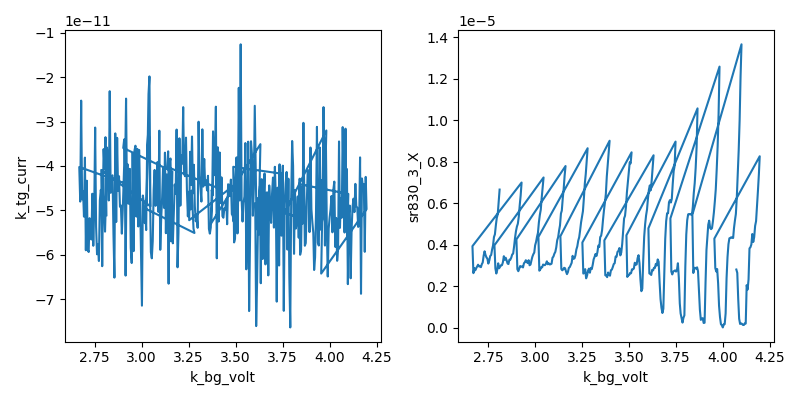

2026-06-23 17:27:08,090 [INFO] Completed in 0h 8m 51s
2026-06-23 17:27:08,090 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\8\data.tsv.gz
2026-06-23 17:27:08,154 [INFO] Ramping k_tg_volt: -3.736 -> 0
2026-06-23 17:27:12,998 [INFO] Ramping k_bg_volt: 2.8125 -> 0


In [19]:
# === Step 1 "map it tight" — (n,D) zoom on the SC candidate (nD-map) ===
# Rasterized polygon around the D=-0.6 dip. B=0 (magnet untouched, pristine).
from sweep import raster
from sharpelab_nb.gates import stack_capacitance, calc_gate_voltages, calc_nD

# --- silent-precondition reads ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T : {_T:.4f} K     (expect base, mK)")
print(f"magnet B   : {_B:.3e} T   (expect ~0 — NOT energised; pristine)")
print(f"gates: k_tg {k_tg.volt()} V  k_bg {k_bg.volt()} V   (parked ~0 after linecuts)")
assert _T < 0.1, "probe not at base"
assert abs(_B) < 5e-3, "magnet not near zero — keep pristine"

# Session calibration (run-4 CNP fit: c_bg/c_tg=1.189, intercept b=+0.0895 V).
c_tg = stack_capacitance([(23.6, 3.0)]); c_bg = 1.189 * c_tg
n_offset = -calc_nD(0.0, 0.0895, c_tg, c_bg)[0]; D_offset = 0.0

# Zoom polygon in (n,D): n[-0.60,-0.35] (1e12 cm^-2), D[-0.68,-0.45] V/nm.
verts = np.array([[-0.60,-0.68],[-0.35,-0.68],[-0.35,-0.45],[-0.60,-0.45],[-0.60,-0.68]])
nx, ny = 31, 14                       # n fast, D slow
xs, ys = raster.rasterize(verts, nx, ny, 0)
vtg, vbg = calc_gate_voltages(xs, ys, c_tg, c_bg, n_offset=n_offset, D_offset=D_offset)
vtg, vbg = sanitize_tg_bg(vtg, vbg, tg_lims, bg_lims)
print(f"zoom: {len(vtg)}/{nx*ny} pts in validators  Vtg[{vtg.min():+.2f},{vtg.max():+.2f}] Vbg[{vbg.min():+.2f},{vbg.max():+.2f}]")

# Resolve R->0 at the dip: raise 4T sensitivity (was ~200uV/rail2.18k -> 20uV/full-scale~200 Ohm).
sr830_3.sensitivity(20e-6)
sr830_1.amplitude(0.1)                # 1 nA AC (SC-safe)
k_tg.nplci(1); k_bg.nplci(1)

meas_config["comment"] = "nD-map zoom on SC candidate: n[-6,-3.5]e11 D[-0.68,-0.45], B=0, sr3 sens 20uV"
s = sweep.AsyncStation(meas_config)
s.add_comment('nD-map')
s.add_comment('SC-candidate zoom: n[-6,-3.5]e11, D[-0.68,-0.45] V/nm; c_bg/c_tg=1.189; B=0; sr3 sens 20uV')

s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); time.sleep(10)
s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(k_bg.volt, k_tg.curr)
s.plot(k_bg.volt, sr830_3.X)
s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=1.2)

s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)


## HERA — Step 2: bias spectroscopy (dV/dI vs I_dc) — the decisive SC test

The (n, D) zoom (run 8) pinned a localized low-R **dome** at the favorable sign, R_xx → **0.09 Ω** (within resolution of zero) at the optimum **(n = −5.2×10¹¹, D = −0.645 V/nm; V_tg = −5.39, V_bg = +4.00)**, deepening toward the gate-limited |D| edge. The 4-wire R_xx→0 hallmark is met at base T / nominal-zero field — but a low-R dome alone is **consistent-with**, not evidence-for (confounds: QAH, a very good metal). The test that separates them is the **nonlinear dV/dI** (`bias-spectroscopy.md`): a superconductor shows a **zero-dV/dI supercurrent plateau that rises sharply at a critical current I_c**; a QAH/metal does not.

**Sweep:** dV/dI vs I_dc at the fixed optimum. DC bias `dc205_1.volt` over **±15 V = ±150 nA** (our full reachable range through the 100 MΩ — an order of magnitude above the ~20 nA reference I_c, so I_c is bracketed unless it's exceptionally large), **151 pts, round-trip** (forward+back) to catch heating/vortex hysteresis. AC kept at **1 nA** (the state survives it — it gave R→0.09 Ω; <<expected I_c); sr3 sensitivity 20 µV (full-scale ~200 Ω resolves the 0 → normal-state ~30–50 Ω rise). `dc205_1.volt` is the direct-set param (no 10 s settle); reset to 0 at the end. **Magnet untouched** (still pristine — field-kill is the next step, Step 3). ~6–8 min.

**Reads:** dV/dI ≈ 0 for |I_dc| < I_c then rising to the normal value = supercurrent → **strong SC**. I_c from the threshold crossing. Watch for I_c⁺ vs I_c⁻ asymmetry (a rigid shift is instrumental; a magnitude asymmetry is physical/nonreciprocal). I'll extract I_c off disk. **Note:** R_xy (the QAH discriminator) isn't wired in the current config — if you have a transverse pair patchable, say so and I'll add a Hall channel; otherwise the supercurrent-lobe shape + the Step-3 field-kill carry the SC/QAH separation. First checkpoint: the first points (I_dc ≈ −150 nA) should sit at the normal dV/dI; near I_dc=0 it should collapse toward 0.


probe MC T  : 0.0337 K     (expect base, mK)
magnet B    : -1.082e-05 T   (expect ~0 — pristine)
gates now   : k_tg 0.0 V  k_bg 0.0 V
dc205_1.volt: 0.0 V   (expect ~0)
2026-06-23 17:32:37,952 [INFO] Ramping k_tg_volt: 0.0 -> -5.39
2026-06-23 17:32:44,884 [INFO] Ramping k_bg_volt: 0.0 -> 4.0
2026-06-23 17:32:49,921 [INFO] Ramping dc205_1_voltage: 0.0 -> -15.0
2026-06-23 17:33:04,554 [INFO] Starting sweep with ID 9
2026-06-23 17:33:04,556 [INFO] Minimum duration 0h 5m 2s


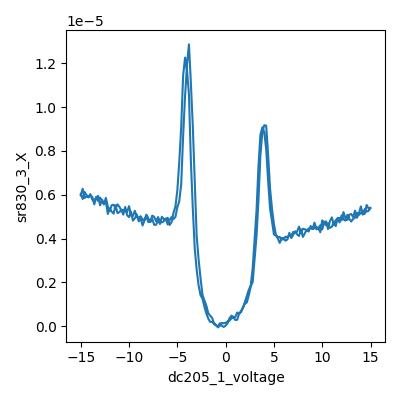

2026-06-23 17:39:08,136 [INFO] Completed in 0h 6m 3s
2026-06-23 17:39:08,136 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\9\data.tsv.gz
2026-06-23 17:39:08,142 [INFO] Ramping dc205_1_voltage: -15.0 -> 0
2026-06-23 17:39:12,958 [INFO] Ramping k_tg_volt: -5.39 -> 0
2026-06-23 17:39:19,899 [INFO] Ramping k_bg_volt: 4.0 -> 0


In [20]:
# === Step 2 — bias spectroscopy: dV/dI vs I_dc at the SC candidate optimum ===
# Operating point n=-5.2e11, D=-0.645 V/nm -> (Vtg=-5.39, Vbg=+4.00). B=0 (pristine).

# --- silent-precondition reads ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T  : {_T:.4f} K     (expect base, mK)")
print(f"magnet B    : {_B:.3e} T   (expect ~0 — pristine)")
print(f"gates now   : k_tg {k_tg.volt()} V  k_bg {k_bg.volt()} V")
print(f"dc205_1.volt: {dc205_1.volt()} V   (expect ~0)")
assert _T < 0.1, "probe not at base"
assert abs(_B) < 5e-3, "magnet not near zero — keep pristine"

VTG_OP, VBG_OP = -5.39, +4.00        # SC dome optimum from run-8 zoom
sr830_1.amplitude(0.1)               # 1 nA AC (state survives it; << expected Ic)
sr830_3.sensitivity(20e-6)           # full-scale ~200 Ohm at 1 nA -> resolves 0..normal
k_tg.nplci(1); k_bg.nplci(1)

# Bias axis: I_dc = V_dc / 100 MOhm.  +/-15 V -> +/-150 nA. Round-trip (hysteresis check).
Vdc = np.linspace(-15.0, 15.0, 151)
Vdc_rt = np.hstack((Vdc, Vdc[::-1]))

meas_config["comment"] = "bias-spec dV/dI vs Idc at SC optimum n=-5.2e11 D=-0.645 (Vtg-5.39 Vbg+4.00), Idc +/-150nA round-trip, B=0"
s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment('SC candidate dV/dI: op (Vtg=-5.39,Vbg=+4.00) n=-5.2e11 D=-0.645; Idc +/-150nA RT; Iac=1nA; B=0')

# Move to operating point, then DC bias to the sweep start; settle.
s.ramp(k_tg.volt, VTG_OP); s.ramp(k_bg.volt, VBG_OP)
s.ramp(dc205_1.volt, Vdc_rt[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(dc205_1.volt, sr830_3.X)      # dV/dI vs bias (live)

try:
    s.sweep(dc205_1.volt, Vdc_rt, delay=1)
finally:
    s.ramp(dc205_1.volt, 0)          # device card: dc205 -> 0 before ending
    s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)


## HERA — Step 3: field-kill / effective-zero (FIRST MAGNET ENERGISATION)

Run 9 gave the supercurrent (I_c ≈ 30 nA). Two strong hallmarks now hold at base T / B=0; the decisive remaining confirmation is the **field response** — a small B⊥ that quenches the low-R / supercurrent while the normal state is ~unchanged counts **strong** for SC and rules out a B-insensitive low-R artifact (`field-sweep-1d.md`, investigation Step 3).

**This is the first time we energise the magnet this session** — all base-T zero-field work is done, so it's the right point, but it leaves pristine field (injects ~mT remanence; expected and fine). **Field discipline (brief):** one-sided, monotonically toward 0 — ramp to the −50 mT extreme, settle, then sweep **−50 mT → 0** (|B| only decreasing). −50 mT is well inside the 100 mT cap and should be past B_c⊥ (mT-scale for proximity SC).

**Measurement:** zero-bias dV/dI (I_dc = 0) vs B⊥ at the SC optimum (gates held at V_tg=−5.39, V_bg=+4.00). dV/dI should rise from ~0 (SC, near effective-zero) to the normal ~55 Ω as |B| grows → that rise is B_c⊥ and the kill; the minimum locates the effective-zero (offset from nominal 0 by the ~2 mT trapped flux). 41 pts (1.25 mT step).

**Also a calibration:** no field ramp yet this session, so I'm pricing conservatively — initial 60 s settle after the −50 mT ramp, **delay 20 s per step**, T monitored every point. If T stays at base, the settle is adequate and I'll tighten it for the follow-ups (Ic(B) map / Fraunhofer); if T spikes near 0 (ramp heating is worst there), I'll lengthen it. ~15–20 min (magnet ramp_rate printed at the top). **Interrupt note:** a kernel interrupt during a field move leaves the supply ramping to its last target — recovery is calling `magnet.field()` again. Run when ready; I'll first-rows-check T + the kill onset off disk.


magnet ramp_rate (T/s): 0.001   current field: -2.0754e-05 T
probe MC T  : 0.0337 K     (expect base, mK)
magnet B    : -2.451e-05 T   (expect ~0 — pristine; we energise BELOW)
dc205_1.volt: 0.0 V  (expect ~0, I_dc=0)
2026-06-23 17:45:23,916 [INFO] Ramping k_tg_volt: 0.0 -> -5.39
2026-06-23 17:45:30,857 [INFO] Ramping k_bg_volt: 0.0 -> 4.0
ramping magnet to -50 mT ...
at -0.049999942 T ; T = 0.0337 K
2026-06-23 17:47:35,039 [INFO] Starting sweep with ID 10
2026-06-23 17:47:35,040 [INFO] Minimum duration 0h 13m 40s


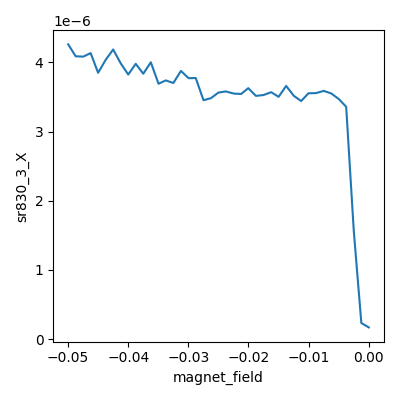

2026-06-23 18:02:21,854 [INFO] Completed in 0h 14m 46s
2026-06-23 18:02:21,855 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\10\data.tsv.gz
2026-06-23 18:02:21,917 [INFO] Ramping k_tg_volt: -5.39 -> 0
2026-06-23 18:02:28,853 [INFO] Ramping k_bg_volt: 4.0 -> 0


In [21]:
# === Step 3 — field-kill / effective-zero: zero-bias dV/dI vs B_perp (FIRST ENERGISATION) ===
# Gates held at SC optimum; I_dc=0. One-sided sweep -50 mT -> 0 (|B| decreasing only).

print("magnet ramp_rate (T/s):", magnet.ramp_rate(), "  current field:", magnet.field(), "T")

# --- silent-precondition reads ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T  : {_T:.4f} K     (expect base, mK)")
print(f"magnet B    : {_B:.3e} T   (expect ~0 — pristine; we energise BELOW)")
print(f"dc205_1.volt: {dc205_1.volt()} V  (expect ~0, I_dc=0)")
assert _T < 0.1, "probe not at base"
assert abs(_B) < 5e-3, "magnet not near zero at start — re-check before energising"

VTG_OP, VBG_OP = -5.39, +4.00
sr830_1.amplitude(0.1); sr830_3.sensitivity(20e-6)
k_tg.nplci(1); k_bg.nplci(1)

meas_config["comment"] = "field-kill: zero-bias dV/dI vs B_perp, SC optimum (Vtg-5.39 Vbg+4.00), B -50mT->0 one-sided, Idc=0"
s = sweep.AsyncStation(meas_config)
s.add_comment('field-sweep-1d')
s.add_comment('SC field-kill/effective-zero: zero-bias dV/dI vs Bperp; -50mT->0; opt n=-5.2e11 D=-0.645')

# operating point + zero DC bias
s.ramp(k_tg.volt, VTG_OP); s.ramp(k_bg.volt, VBG_OP)
dc205_1.volt(0)

# ENERGISE to the -50 mT extreme, then settle (first field move; conservative).
print("ramping magnet to -50 mT ...")
magnet.field(-0.050)          # blocks until holding
time.sleep(60)                # thermal settle after the big ramp
print("at", magnet.field(), "T ; T =", temperature(), "K")

s.fp(temperature)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(magnet.field, sr830_3.X)

# Sweep one-sided toward 0 (|B| monotonically decreasing).
s.sweep(magnet.field, np.linspace(-0.050, 0.0, 41), delay=20)

# Leave magnet at 0 (holds; ~mT remanence now present). Park gates.
s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)


## HERA — Step 3: Ic(B) / Fraunhofer map (both polarities) — last base-T field run

Field-kill (run 10) gave B_c⊥ ≈ 4 mT and effective-zero ≈ 0. This maps **dV/dI vs (I_dc, B⊥)** to extract **I_c(B)** — a cleaner B_c⊥ (where I_c→0), the effective-zero (where I_c is maximal), and an **attempt at phase-coherent (Fraunhofer-like) I_c oscillations** (`fraunhofer.md`, investigation Step 3). Per the investigation, I sweep **both polarities** so the kill mirrors about the effective-zero (a real SC mirrors; an artifact need not).

**Two one-sided maps** (field discipline — every measurement sweep has |B| decreasing toward 0): side A −6 mT → 0, side B +6 mT → 0; between them a positioning ramp 0→+6 mT with a settle. B step 0.4 mT (16/side), I_dc ±50 nA (25 pts, brackets I_c≈30 nA), at the SC optimum (V_tg=−5.39, V_bg=+4.00). **Settle shortened to 6 s** (run 10 showed zero field-heating at 20 s). Reports as **consistent-with phase coherence** if I_c modulates — I will *not* over-name the microscopic origin (weak-link vs finite-size both viable). ~25–30 min total (two runs); longest run this session — interrupt after side A if you're time-constrained and I'll work with the negative side.

**Reads:** I_c(B) should peak at effective-zero and fall to 0 by ~±4 mT (mirrored). Any periodic I_c modulation → Φ₀/area gives the junction area (consistent-with phase coherence). First-rows check: at B=−6 mT (SC dead) dV/dI should be ~normal at all I_dc; as |B|→0 the zero-bias plateau reopens. After this: **heat up for T-dependence (Tc) — the last hallmark**, then the five-part call.


magnet ramp_rate (T/s): 0.001  field: 1.545e-06 T
probe MC T 0.0337 K ; magnet 2.539e-05 T ; dc205 0.0 V
2026-06-23 18:10:43,287 [INFO] Ramping k_tg_volt: 0.0 -> -5.39
2026-06-23 18:10:50,220 [INFO] Ramping k_bg_volt: 0.0 -> 4.0
[neg] ramping magnet to -6 mT ...
[neg] at -0.00597 T ; T = 0.0337 K
2026-06-23 18:11:39,653 [INFO] Starting megasweep with ID 11
2026-06-23 18:11:39,653 [INFO] Minimum duration 0h 8m 16s


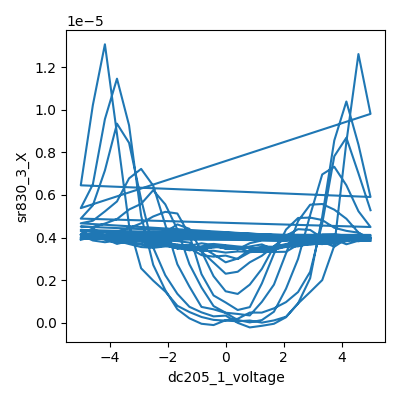

2026-06-23 18:22:42,452 [INFO] Completed in 0h 11m 2s
2026-06-23 18:22:42,453 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\11\data.tsv.gz
[pos] ramping magnet to +6 mT ...
[pos] at 0.00600 T ; T = 0.0337 K
2026-06-23 18:23:30,259 [INFO] Starting megasweep with ID 12
2026-06-23 18:23:30,261 [INFO] Minimum duration 0h 8m 16s


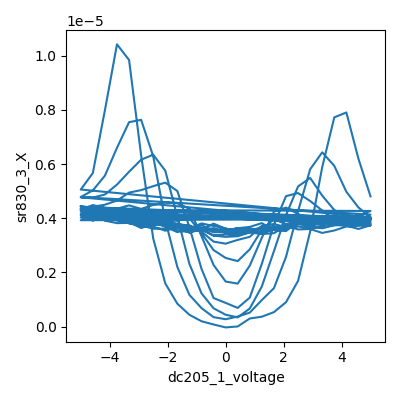

2026-06-23 18:34:26,657 [INFO] Completed in 0h 10m 56s
2026-06-23 18:34:26,657 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\12\data.tsv.gz
2026-06-23 18:34:28,327 [INFO] Ramping k_tg_volt: -5.39 -> 0
2026-06-23 18:34:35,261 [INFO] Ramping k_bg_volt: 4.0 -> 0


In [22]:
# === Step 3 — Ic(B)/Fraunhofer: dV/dI vs (I_dc, B_perp), both polarities ===
# Two one-sided megasweeps (|B| decreasing toward 0). SC optimum; B=0 start.

print("magnet ramp_rate (T/s):", magnet.ramp_rate(), " field:", magnet.field(), "T")
_T = temperature(); _B = magnet.field()
print(f"probe MC T {_T:.4f} K ; magnet {_B:.3e} T ; dc205 {dc205_1.volt()} V")
assert _T < 0.1, "probe not at base"
assert abs(_B) < 5e-3, "magnet not near 0 at start (run-10 left it at 0)"

VTG_OP, VBG_OP = -5.39, +4.00
Vdc = np.linspace(-5.0, 5.0, 25)          # +/-50 nA (brackets Ic~30 nA)
sides = [("neg", np.linspace(-0.006, 0.0, 16), -0.006),
         ("pos", np.linspace(+0.006, 0.0, 16), +0.006)]
sr830_1.amplitude(0.1); sr830_3.sensitivity(20e-6); k_tg.nplci(1); k_bg.nplci(1)

for i, (side, B_vec, B_start) in enumerate(sides):
    meas_config["comment"] = f"Ic(B)/fraunhofer {side}: B {B_start*1e3:+.0f}mT->0, Idc+/-50nA, opt n=-5.2e11 D=-0.645"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('fraunhofer')
    s.add_comment(f'Ic(B) {side} side: B {B_start*1e3:+.0f}mT->0; Idc+/-50nA; opt Vtg-5.39 Vbg+4.00')
    if i == 0:
        s.ramp(k_tg.volt, VTG_OP); s.ramp(k_bg.volt, VBG_OP)
    dc205_1.volt(0)
    print(f"[{side}] ramping magnet to {B_start*1e3:+.0f} mT ...")
    magnet.field(B_start); time.sleep(30)
    print(f"[{side}] at {magnet.field():.5f} T ; T = {temperature():.4f} K")
    s.fp(temperature); s.fp(magnet.field)
    s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(dc205_1.volt)
    for lia in (sr830_1, sr830_2, sr830_3):
        s.fp(lia.X).fp(lia.P)
    s.plot(dc205_1.volt, sr830_3.X)
    s.megasweep(magnet.field, B_vec, dc205_1.volt, Vdc, slow_delay=6, fast_delay=1)

# Park: dc bias 0, magnet 0, gates 0.
dc205_1.volt(0)
magnet.field(0.0)
s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)


## HERA — Step 4: T-dependence (Ic(T)) — HEAT UP, the long final phase

This is the **last** measurement (heat up last). Everything at base T is done — the SC is `superconductor (strong)` on five lines of evidence (R_xx→0, supercurrent I_c≈30 nA, (n,D) dome, field-kill B_c⊥≈3 mT, uniform-2D from the single-dome I_c(B)). The remaining hallmark for a **decisive** call + the Tc number: **I_c collapses to 0 at Tc**.

**Flavor-B ladder** (`temperature-dependence.md`): the same bias sweep (dV/dI vs I_dc, ±50 nA) repeated at the fixed SC optimum (V_tg=−5.39, V_bg=+4.00, B≈0), **heater stepped DOWN** (5→4→3→2→1→0 V, measure-while-cooling) — a **coarse survey first** to bracket Tc, refine after. Heater discipline (rig card): ≤1 V steps, **5 min equilibration per 1 V**, T **read back from the logfile** (open-loop — the V→T table is a prior), `heater.curr` checked nonzero each rung (an open heater = a fake ladder). Device-card V→T: 4.5 V≈250 mK, 6 V≈423 mK — so 5 V (~300 mK) should sit above Tc for a state this fragile; if I_c is still strong at the top, we extend up.

**Cost: ~1 h for the ladder + ~1 h to recool to base afterward** — the thermal cycle is the expensive step. **This is a genuine fork on your fridge time:** run cell X to commit the T-ladder now and get Tc (→ decisive call), or we can **wrap here** with the strong 5-hallmark characterization and write the call, doing T-dependence next session. Either is a clean outcome. If you run it: watch for fridge instability (heating can trip the mixture); interrupt anytime — partial rungs are still readable. I'll read Tc off the I_c(T) collapse and write the five-part call.


start: T 0.0337 K  B 1.545e-06 T  heater 0.0 V curr 2.07e-07 A
heater 5.0 V -> T 34 mK, heater.curr 4.626e-04 A
2026-06-23 19:06:06,906 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:06:08,404 [INFO] Starting sweep with ID 13
2026-06-23 19:06:08,405 [INFO] Minimum duration 0h 0m 25s


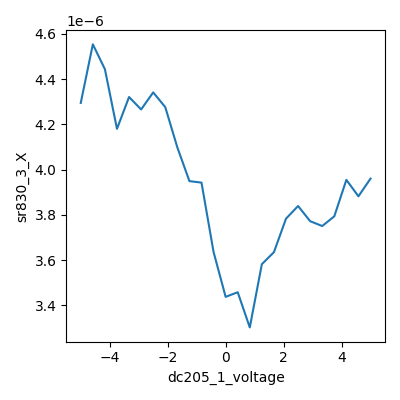

2026-06-23 19:06:40,690 [INFO] Completed in 0h 0m 31s
2026-06-23 19:06:40,690 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\13\data.tsv.gz


KeyboardInterrupt: 

In [23]:
# === Step 4 — T-dependence: Ic(T) ladder (HEAT UP last). Flavor B, heater stepped DOWN. ===
# Fixed point: SC optimum (Vtg=-5.39, Vbg=+4.00), B~0. Bias sweep dV/dI vs Idc at each T.

_T = temperature(); _B = magnet.field()
print(f"start: T {_T:.4f} K  B {_B:.3e} T  heater {heater.volt()} V curr {heater.curr():.2e} A")
assert _T < 0.1, "not at base at start — let it cool first"
assert abs(_B) < 5e-3, "magnet not ~0"

VTG_OP, VBG_OP = -5.39, +4.00
Vdc = np.linspace(-5.0, 5.0, 25)          # +/-50 nA (brackets Ic~30nA; Ic only shrinks with T)
ladder = [5.0, 4.0, 3.0, 2.0, 1.0, 0.0]   # heater V, DESCENDING (measure while cooling)

sr830_1.amplitude(0.1); sr830_3.sensitivity(20e-6); k_tg.nplci(1); k_bg.nplci(1)

def heater_to(v_target):
    """Ramp heater in <=1V steps with a 5min/1V equilibration hold (rig-card discipline)."""
    v0 = float(heater.volt())
    if abs(v_target - v0) < 1e-6:
        return
    d = np.sign(v_target - v0); v = v0
    while abs(v - v_target) > 1e-6:
        dv = d * min(1.0, abs(v_target - v)); v = round(v + dv, 4)
        heater.volt(v); time.sleep(1)
        cur = heater.curr()
        assert abs(cur) > 1e-9 or v == 0.0, f"heater drawing ~0 A at {v} V — open line?"
        time.sleep(5*60 * abs(dv)/1.0)     # 5 min per 1 V, proportional

# fixed point (B left at nominal 0 ~ effective-zero within the mT remanence)
k_tg.volt(VTG_OP); k_bg.volt(VBG_OP)

for hv in ladder:
    heater_to(hv)
    Tnow = temperature(); cur = heater.curr()
    print(f"heater {hv} V -> T {Tnow*1e3:.0f} mK, heater.curr {cur:.3e} A")

    meas_config["comment"] = f"Ic(T) rung: heater {hv}V, T~{Tnow*1e3:.0f}mK, Idc+/-50nA, opt, B~0"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('temperature-dependence')
    s.add_comment(f'Ic(T): heater {hv}V T~{Tnow*1e3:.0f}mK; Idc+/-50nA; opt Vtg-5.39 Vbg+4.00; B~0')
    s.ramp(dc205_1.volt, Vdc[0])
    s.fp(temperature); s.fp(fridge_temperature); s.fp(magnet.field)
    s.fp(heater.volt); s.fp(heater.curr)
    s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(dc205_1.volt)
    for lia in (sr830_1, sr830_2, sr830_3):
        s.fp(lia.X).fp(lia.P)
    s.plot(dc205_1.volt, sr830_3.X)
    s.sweep(dc205_1.volt, Vdc, delay=1)
    dc205_1.volt(0)

# heater off; cool to base (~1 h). Park gates. Next cell must assert T back near base.
heater.volt(0)
k_tg.volt(0); k_bg.volt(0)
print("ladder done; heater OFF — allow ~1 h to recool to base before base-T work.")


## HERA — ABORT T-ladder: park heater + diagnose stale thermometry

**Stop reason:** at heater = 5 V the heater drew 0.46 mA (2.3 mW) and the supercurrent was killed (dV/dI flat 39 Ω), yet `temperature()` read **33.7 mK — exactly base, unchanged**, the same value it has reported in *every* run this session. That is the `temperature-dependence` Verify signature of a **stale/frozen T logfile** (dead thermometry worker, or a format/column change, or `temperature` pointed at a sensor that doesn't see the sample). Tc is not extractable until this is fixed, and heating blind (my `assert T<0.1` is defeated by the frozen value) is unsafe. The device wasn't endangered (heater ≤5 V ≪ the 6.5 V ceiling, and the cold base-T physics is genuine), but the ladder data is not Tc-usable.

**This cell:** (1) parks the heater to 0 to recool; (2) diagnoses — samples `temperature()` repeatedly (frozen?), checks the probe-MC logfile's modification time + last line (is the worker still writing?), and reads `fridge_temperature` / `mag_temperature` (are the *other* sensors live, or all frozen?). That separates dead-worker (all stale, file not updating) from wrong-sensor/format (file fresh but value pinned).

**Operator:** please also glance at the launcher **health panel** for the AVS probe-bridge worker, and confirm the loaded probe / sample-thermometer logfile is the right one (the setup cell carried a `# <-- verify probe` on `Probe2_MixingCh_low.txt`). I'm holding all measurement until T reads true — once it does, the Ic(T) ladder is a quick redo.


In [24]:
# === ABORT T-ladder: park heater, diagnose stale thermometry ===
import os, time as _t

heater.volt(0)                      # park heater -> cool down
print("heater ->", heater.volt(), "V ; heater.curr", heater.curr(), "A")

# 1) is temperature() frozen? sample over ~10 s
vals = []
for _ in range(5):
    vals.append(round(float(temperature()), 5)); _t.sleep(2)
print("temperature() x5 over 10 s:", vals, "->", "FROZEN" if len(set(vals)) == 1 else "moving")

# 2) probe-MC logfile freshness (is the worker still writing?)
lf = r"C:\Users\toploader\temperature_logs\Probe2_MixingCh_low.txt"
try:
    age = _t.time() - os.path.getmtime(lf)
    print(f"probe-MC logfile age: {age:.0f} s (mtime {_t.ctime(os.path.getmtime(lf))})")
    with open(lf) as f:
        tail = f.readlines()[-2:]
    print("last lines:", [l.strip() for l in tail])
except Exception as e:
    print("logfile read error:", e)

# 3) are the other sensors live (or all frozen)?
print("fridge_temperature:", fridge_temperature(), "K ; mag_temperature:", mag_temperature(), "K")
print("--> dead worker if logfile age is large & value frozen; wrong-sensor/format if file is fresh but pinned.")


heater -> 0.0 V ; heater.curr 1.744193e-07 A
temperature() x5 over 10 s: [0.0337, 0.0337, 0.0337, 0.0337, 0.0337] -> FROZEN
probe-MC logfile age: 280989 s (mtime Sat Jun 20 13:10:23 2026)
last lines: ['1781986197\tSat Jun 20 13:09:57 2026\t  33003.00\t   0.03373\tIdle', '1781986218\tSat Jun 20 13:10:18 2026\t  33032.00\t   0.03370\tIdle']
fridge_temperature: 0.0 K ; mag_temperature: 0.0 K
--> dead worker if logfile age is large & value frozen; wrong-sensor/format if file is fresh but pinned.


## HERA — Thermometry fix: re-point sample T to Probe1 (supersedes cell 8's Probe2)

Operator: **Probe1** is the live sample thermometer; the setup cell pointed `temperature` at **Probe2_MixingCh_low** (stale — pinned 33.7 mK all session). My mistake was trusting the template's `# <-- verify probe` Probe2 default instead of checking which probe logfile was actually advancing. Lesson logged: **check both probe logfiles and pick the non-stale one** by default.

This cell parks the heater (safety), reads **both** probe logfiles (value + file age) to show which is live, then **redefines `temperature` to Probe1** for all downstream cells. **Decisive confirmation built in:** the sample was just heated to ~5 V (SC killed) and is now cooling — the *live* sensor (Probe1) should read **elevated T (≫34 mK) and falling**, while the stale Probe2 still shows ~33.7 mK. If Probe1 shows that, we've found the real thermometer; I then wait for it to recool to base and re-run the Ic(T) ladder (a quick redo — we know the SC is gone by ~5 V).


In [25]:
# === Thermometry fix: park heater, check BOTH probes, re-point `temperature` to Probe1 ===
import os, time as _t

heater.volt(0)
print("heater ->", heater.volt(), "V ; curr", heater.curr(), "A\n")

probes = {
    "Probe1": r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt",
    "Probe2": r"C:\Users\toploader\temperature_logs\Probe2_MixingCh_low.txt",
}
for name, lf in probes.items():
    try:
        p = temperature_from_logfile("T", lf)
        v1 = float(p()); _t.sleep(3); v2 = float(p())
        age = _t.time() - os.path.getmtime(lf)
        live = "LIVE" if age < 120 else "STALE(file old)"
        print(f"{name}: T {v1*1e3:.1f} -> {v2*1e3:.1f} mK | logfile age {age:.0f}s | {live}")
    except Exception as e:
        print(f"{name}: error {e}")

# Re-point the sample thermometer to Probe1 (live). Supersedes setup cell 8 (Probe2).
temperature = temperature_from_logfile("T", probes["Probe1"])
print(f"\nsample T (Probe1) now: {temperature()*1e3:.1f} mK   "
      f"(expect ELEVATED & falling if Probe1 is the real sample sensor — we just heated to 5 V)")


heater -> 0.0 V ; curr 2.068365e-07 A

Probe1: T 120.7 -> 120.7 mK | logfile age 20s | LIVE
Probe2: T 33.7 -> 33.7 mK | logfile age 281320s | STALE(file old)

sample T (Probe1) now: 117.3 mK   (expect ELEVATED & falling if Probe1 is the real sample sensor — we just heated to 5 V)


## HERA — Ic(T) by measure-while-cooling (real T = Probe1), heater OFF

Probe1 confirmed live (120→117 mK, falling; Probe2 dead 3.3 days). The sample is cooling through (possibly) the SC transition **right now** — so instead of re-heating, I capture I_c(T) on the natural cooldown: a loop of dV/dI vs I_dc sweeps (±50 nA, at the SC optimum, B≈0), each tagged with the **real** Probe1 T, until it reaches base (break at T<40 mK). Heater is OFF (parked).

**Immediate read:** the first sweep is at ~110 mK. If I_c is already finite there, Tc > 110 mK and I'll re-heat for a controlled ladder above Tc; if I_c≈0 and grows as it cools, we're capturing the transition directly → Tc from the I_c onset. Each sweep ~30 s, so points are ~30 s / a few-mK apart through the transition (T drifts only ~1–2 mK within a 30 s sweep near here — fine). Precondition now includes a real **staleness guard** (Probe1 logfile must be advancing), the check that was missing. ~10–15 min. I'll read the first sweep off disk and the full I_c(T) at the end.


heater 0.0 V (OFF) ; Probe1 T 98.9 mK (age 15s)
[0] T = 98.9 mK
2026-06-23 19:21:17,514 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:21:19,060 [INFO] Starting sweep with ID 14
2026-06-23 19:21:19,061 [INFO] Minimum duration 0h 0m 25s


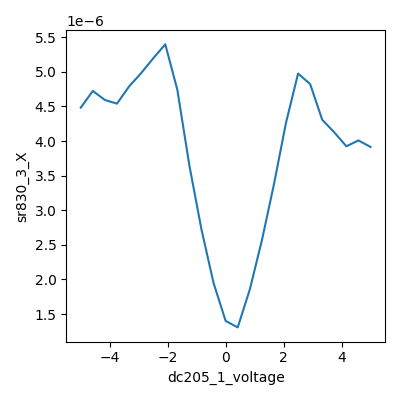

2026-06-23 19:21:50,880 [INFO] Completed in 0h 0m 31s
2026-06-23 19:21:50,881 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\14\data.tsv.gz
[1] T = 92.0 mK
2026-06-23 19:21:52,310 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:21:53,839 [INFO] Starting sweep with ID 15
2026-06-23 19:21:53,840 [INFO] Minimum duration 0h 0m 25s


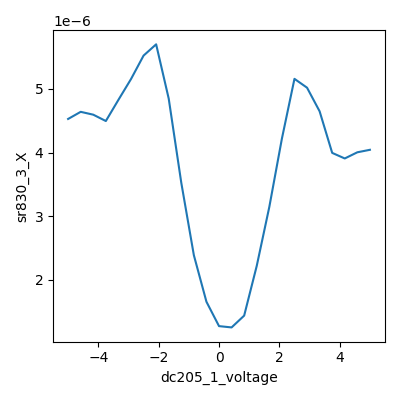

2026-06-23 19:22:25,915 [INFO] Completed in 0h 0m 31s
2026-06-23 19:22:25,915 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\15\data.tsv.gz
[2] T = 84.2 mK
2026-06-23 19:22:27,377 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:22:28,929 [INFO] Starting sweep with ID 16
2026-06-23 19:22:28,930 [INFO] Minimum duration 0h 0m 25s


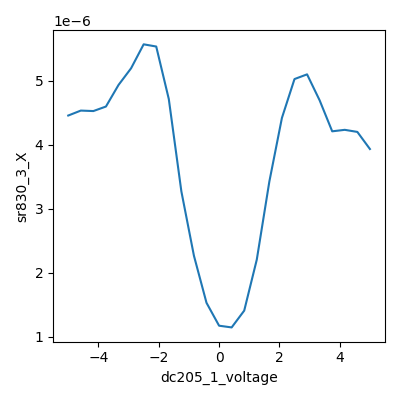

2026-06-23 19:23:00,851 [INFO] Completed in 0h 0m 31s
2026-06-23 19:23:00,852 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\16\data.tsv.gz
[3] T = 80.7 mK
2026-06-23 19:23:02,334 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:23:03,872 [INFO] Starting sweep with ID 17
2026-06-23 19:23:03,872 [INFO] Minimum duration 0h 0m 25s


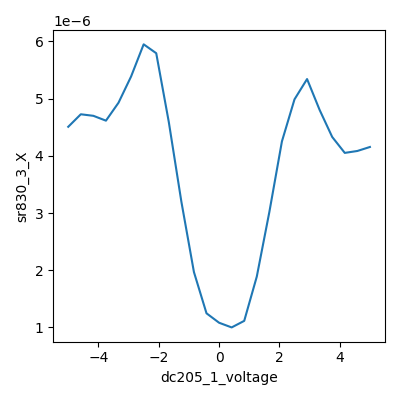

2026-06-23 19:23:35,741 [INFO] Completed in 0h 0m 31s
2026-06-23 19:23:35,742 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\17\data.tsv.gz
[4] T = 73.8 mK
2026-06-23 19:23:37,208 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:23:38,741 [INFO] Starting sweep with ID 18
2026-06-23 19:23:38,741 [INFO] Minimum duration 0h 0m 25s


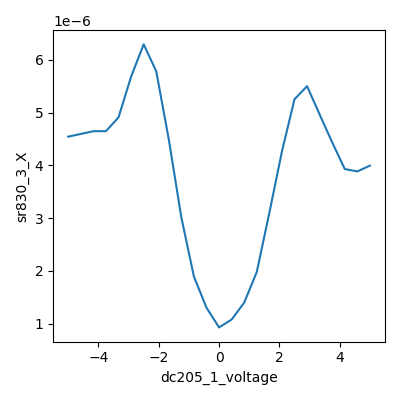

2026-06-23 19:24:10,794 [INFO] Completed in 0h 0m 31s
2026-06-23 19:24:10,794 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\18\data.tsv.gz
[5] T = 67.8 mK
2026-06-23 19:24:12,259 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:24:13,823 [INFO] Starting sweep with ID 19
2026-06-23 19:24:13,824 [INFO] Minimum duration 0h 0m 25s


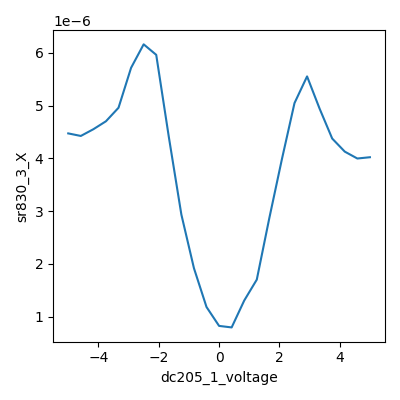

2026-06-23 19:24:45,672 [INFO] Completed in 0h 0m 31s
2026-06-23 19:24:45,673 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\19\data.tsv.gz
[6] T = 62.5 mK
2026-06-23 19:24:47,119 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:24:48,681 [INFO] Starting sweep with ID 20
2026-06-23 19:24:48,682 [INFO] Minimum duration 0h 0m 25s


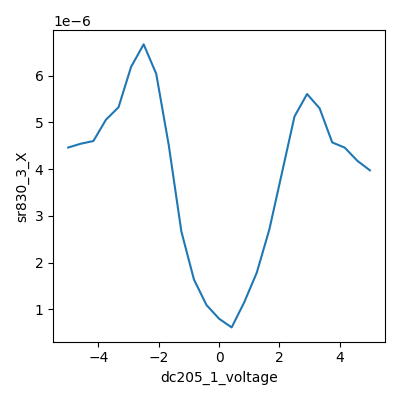

2026-06-23 19:25:20,611 [INFO] Completed in 0h 0m 31s
2026-06-23 19:25:20,613 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\20\data.tsv.gz
[7] T = 60.2 mK
2026-06-23 19:25:22,074 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:25:23,644 [INFO] Starting sweep with ID 21
2026-06-23 19:25:23,645 [INFO] Minimum duration 0h 0m 25s


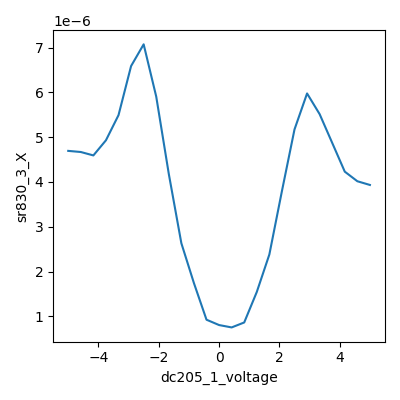

2026-06-23 19:25:55,581 [INFO] Completed in 0h 0m 31s
2026-06-23 19:25:55,582 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\21\data.tsv.gz
[8] T = 56.0 mK
2026-06-23 19:25:57,031 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:25:58,582 [INFO] Starting sweep with ID 22
2026-06-23 19:25:58,583 [INFO] Minimum duration 0h 0m 25s


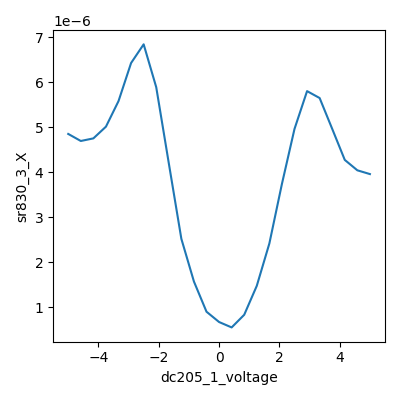

2026-06-23 19:26:30,500 [INFO] Completed in 0h 0m 31s
2026-06-23 19:26:30,500 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\22\data.tsv.gz
[9] T = 0.0 mK
2026-06-23 19:26:31,954 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:26:33,469 [INFO] Starting sweep with ID 23
2026-06-23 19:26:33,470 [INFO] Minimum duration 0h 0m 25s


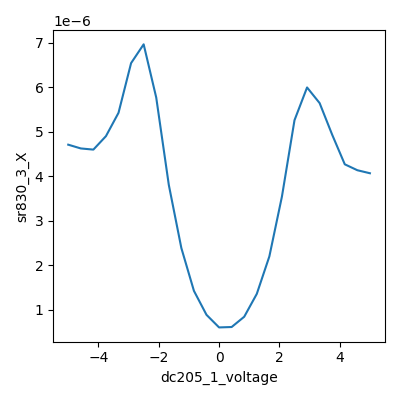

2026-06-23 19:27:05,321 [INFO] Completed in 0h 0m 31s
2026-06-23 19:27:05,322 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\23\data.tsv.gz
reached base; stopping cooldown trace.
done. temperature() now: 0.0 mK


In [26]:
# === Ic(T) measure-while-cooling: dV/dI vs Idc as the sample cools (real T=Probe1) ===
import os, time as _t
# staleness guard: Probe1 logfile must be advancing (the check that was missing)
_lf = r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"
_age = _t.time() - os.path.getmtime(_lf)
assert _age < 120, f"Probe1 logfile stale ({_age:.0f}s old) — thermometry worker down"
print(f"heater {heater.volt()} V (OFF) ; Probe1 T {temperature()*1e3:.1f} mK (age {_age:.0f}s)")
assert heater.volt() == 0, "heater not parked"

VTG_OP, VBG_OP = -5.39, +4.00
Vdc = np.linspace(-5.0, 5.0, 25)          # +/-50 nA
sr830_1.amplitude(0.1); sr830_3.sensitivity(20e-6); k_tg.nplci(1); k_bg.nplci(1)
k_tg.volt(VTG_OP); k_bg.volt(VBG_OP)

for i in range(24):
    Tnow = float(temperature())
    print(f"[{i}] T = {Tnow*1e3:.1f} mK")
    meas_config["comment"] = f"Ic(T) cooldown #{i}: T~{Tnow*1e3:.1f}mK, Idc+/-50nA, opt, B~0, heater OFF"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('temperature-dependence')
    s.add_comment(f'Ic(T) cooldown trace #{i}: T~{Tnow*1e3:.1f}mK (Probe1); Idc+/-50nA; opt; B~0')
    s.ramp(dc205_1.volt, Vdc[0])
    s.fp(temperature); s.fp(magnet.field)
    s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(dc205_1.volt)
    for lia in (sr830_1, sr830_2, sr830_3):
        s.fp(lia.X).fp(lia.P)
    s.plot(dc205_1.volt, sr830_3.X)
    s.sweep(dc205_1.volt, Vdc, delay=1)
    dc205_1.volt(0)
    if Tnow < 0.040:                       # reached base — stop
        print("reached base; stopping cooldown trace.")
        break

k_tg.volt(0); k_bg.volt(0)
print("done. temperature() now:", temperature()*1e3, "mK")


## HERA — Tc ladder: controlled re-heat to pin the Ic collapse (run AFTER cooldown reaches base)

The cooldown trace gives the **lower branch** I_c(T) (34–95 mK, I_c climbing to ~30 nA). The **collapse** (I_c→0 = Tc) sits above ~95 mK and was missed (we started below it). This is the controlled complement: with Probe1 now live, warm to ~250 mK (above the extrapolated Tc≈120–150 mK) and step the heater **down** through the transition, a bias sweep + real T at each rung. Top rung should show **I_c=0** (normal); descending rungs catch I_c reappearing → Tc from the onset.

**Discipline:** ≤1 V heater steps, 5 min/1 V equilibration, `heater.curr` checked nonzero, **real T read from Probe1** each rung (staleness-guarded). Ladder heater V = [4.5, 3.0, 2.5, 2.0, 1.5] (≈250→~100 mK; I read T back — if 4.5 V isn't above Tc, I extend up). ~30–35 min + recool after. **Precondition: sample at base (Probe1 < 50 mK)** — so run this only once the cooldown cell has finished and the sample is cold. Combined with the cooldown's lower branch, this gives the full I_c(T) and Tc → the decisive call.


start: Probe1 T 48.6 mK, heater 0.0 V
heater 4.5 V -> Probe1 T 244.5 mK, curr 3.929e-04 A
2026-06-23 19:55:07,214 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 19:55:08,708 [INFO] Starting sweep with ID 24
2026-06-23 19:55:08,709 [INFO] Minimum duration 0h 0m 25s


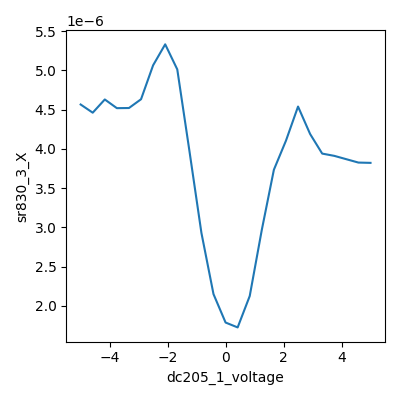

2026-06-23 19:55:41,107 [INFO] Completed in 0h 0m 32s
2026-06-23 19:55:41,108 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\24\data.tsv.gz
heater 3.0 V -> Probe1 T 183.4 mK, curr 2.122e-04 A
2026-06-23 20:03:16,706 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:03:18,218 [INFO] Starting sweep with ID 25
2026-06-23 20:03:18,218 [INFO] Minimum duration 0h 0m 25s


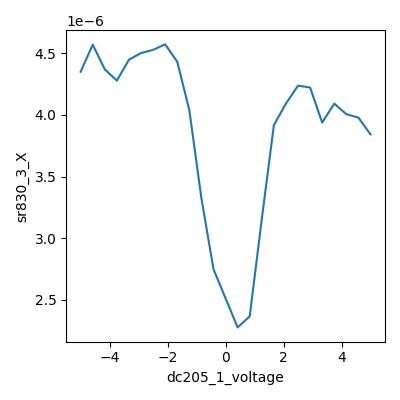

2026-06-23 20:03:50,348 [INFO] Completed in 0h 0m 31s
2026-06-23 20:03:50,349 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\25\data.tsv.gz
heater 2.5 V -> Probe1 T 157.5 mK, curr 1.617e-04 A
2026-06-23 20:06:23,611 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:06:25,140 [INFO] Starting sweep with ID 26
2026-06-23 20:06:25,141 [INFO] Minimum duration 0h 0m 25s


2026-06-23 20:06:55,786 [WARNING] ID 26 INTERRUPTED


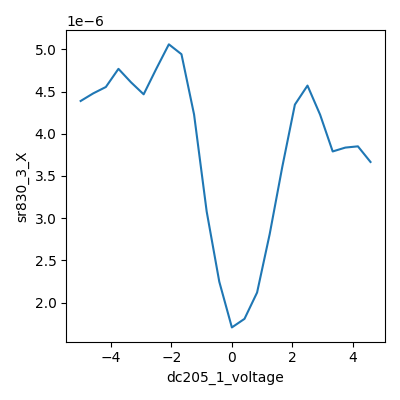

2026-06-23 20:06:56,158 [INFO] Completed in 0h 0m 30s
2026-06-23 20:06:56,158 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\26\data.tsv.gz
heater 2.0 V -> Probe1 T 130.3 mK, curr 1.165e-04 A
2026-06-23 20:09:29,318 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:09:30,804 [INFO] Starting sweep with ID 27
2026-06-23 20:09:30,805 [INFO] Minimum duration 0h 0m 25s


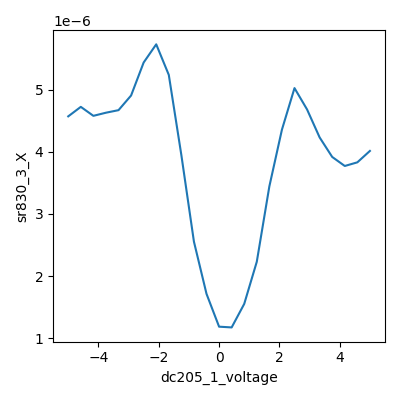

2026-06-23 20:10:03,008 [INFO] Completed in 0h 0m 31s
2026-06-23 20:10:03,009 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\27\data.tsv.gz
heater 1.5 V -> Probe1 T 106.1 mK, curr 7.676e-05 A
2026-06-23 20:12:36,270 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:12:37,764 [INFO] Starting sweep with ID 28
2026-06-23 20:12:37,765 [INFO] Minimum duration 0h 0m 25s


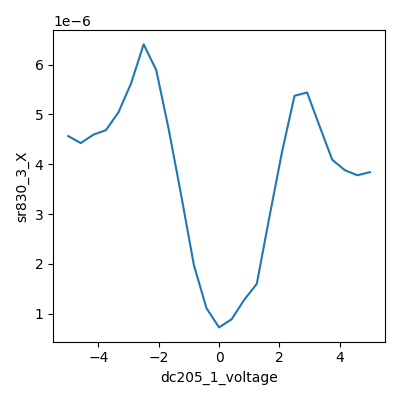

2026-06-23 20:13:10,509 [INFO] Completed in 0h 0m 32s
2026-06-23 20:13:10,511 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\28\data.tsv.gz
Tc ladder done; heater OFF -> recool. temperature() now: 103.04 mK


In [28]:
# === Tc ladder: controlled re-heat, heater stepped DOWN through the transition (real T=Probe1) ===
import os, time as _t
_lf = r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"
assert _t.time() - os.path.getmtime(_lf) < 120, "Probe1 logfile stale — thermometry worker down"
_T0 = float(temperature())
print(f"start: Probe1 T {_T0*1e3:.1f} mK, heater {heater.volt()} V")
assert _T0 < 0.050, "sample not at base yet — let the cooldown finish first"
assert abs(magnet.field()) < 5e-3, "magnet not ~0"

VTG_OP, VBG_OP = -5.39, +4.00
Vdc = np.linspace(-5.0, 5.0, 25)
ladder = [4.5, 3.0, 2.5, 2.0, 1.5]        # heater V, DESCENDING (warm to top first, measure while cooling)
sr830_1.amplitude(0.1); sr830_3.sensitivity(20e-6); k_tg.nplci(1); k_bg.nplci(1)

def heater_to(v_target):
    v0 = float(heater.volt())
    if abs(v_target - v0) < 1e-6: return
    d = np.sign(v_target - v0); v = v0
    while abs(v - v_target) > 1e-6:
        dv = d*min(1.0, abs(v_target - v)); v = round(v+dv, 4)
        heater.volt(v); _t.sleep(1)
        assert abs(heater.curr()) > 1e-9 or v == 0.0, f"heater ~0 A at {v} V — open line"
        _t.sleep(5*60*abs(dv)/1.0)

k_tg.volt(VTG_OP); k_bg.volt(VBG_OP)
for hv in ladder:
    heater_to(hv)
    Tnow = float(temperature()); cur = heater.curr()
    print(f"heater {hv} V -> Probe1 T {Tnow*1e3:.1f} mK, curr {cur:.3e} A")
    meas_config["comment"] = f"Tc ladder: heater {hv}V, T~{Tnow*1e3:.1f}mK, Idc+/-50nA, opt, B~0"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('temperature-dependence')
    s.add_comment(f'Tc ladder rung: heater {hv}V T~{Tnow*1e3:.1f}mK (Probe1); Idc+/-50nA; opt; B~0')
    s.ramp(dc205_1.volt, Vdc[0])
    s.fp(temperature); s.fp(magnet.field); s.fp(heater.volt); s.fp(heater.curr)
    s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(dc205_1.volt)
    for lia in (sr830_1, sr830_2, sr830_3):
        s.fp(lia.X).fp(lia.P)
    s.plot(dc205_1.volt, sr830_3.X)
    s.sweep(dc205_1.volt, Vdc, delay=1)
    dc205_1.volt(0)

heater.volt(0); k_tg.volt(0); k_bg.volt(0)
print("Tc ladder done; heater OFF -> recool. temperature() now:", temperature()*1e3, "mK")


## HERA — Tc collapse: high-T cooling ladder (warm above Tc, step DOWN)

Redirected from the descending ladder (which was heading into low-T territory the cooldown already covers). The traces show a **broad 2D fluctuation transition**: at 246 mK the dV/dI dip is shallow (~17 Ω) and at 182 mK shallower (~23 Ω) — both far from the deep base-T dip (~6 Ω). The **onset Tc (dip→normal, I_c→0)** sits in 246–320 mK (5 V/run-13 was flat-normal). This ladder pins it: warm to **5.5 V (~380 mK, above Tc)**, then step **down** [5.5, 5.25, 5.0, 4.75, 4.5] (≈380→246 mK), bias sweep + real Probe1 T at each — **measure-while-cooling** (each rung approached from above, the reliable direction; avoids the warm-up artifact that made the 246 mK first rung noisy).

**Reads:** at 5.5 V the dV/dI should be **flat-normal (no dip, I_c=0)**; as it cools the zero-bias dip reappears → the onset Tc where it first deviates. Combined with the cooldown's lower branch, this is the full dV/dI(I_dc, T) and Tc (onset; I'll note the broad-transition / T_BKT caveat — a 2D SC has a mean-field onset above a lower zero-resistance T_BKT). Sample is currently ~150 mK (mid-interrupt), heater ~3 V — this warms up from there. ~20–25 min. Then I write the call.


start: Probe1 T 103.0 mK, heater 0.0 V, curr 2.05e-07 A
heater 5.5 V -> Probe1 T 325.5 mK, curr 5.375e-04 A
2026-06-23 20:41:21,898 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:41:23,401 [INFO] Starting sweep with ID 29
2026-06-23 20:41:23,401 [INFO] Minimum duration 0h 0m 25s


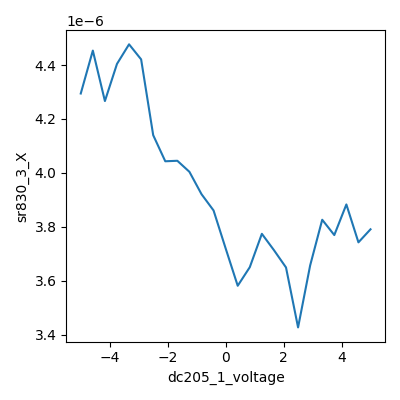

2026-06-23 20:41:55,652 [INFO] Completed in 0h 0m 31s
2026-06-23 20:41:55,653 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\29\data.tsv.gz
heater 5.25 V -> Probe1 T 327.9 mK, curr 4.995e-04 A
2026-06-23 20:43:13,601 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:43:15,098 [INFO] Starting sweep with ID 30
2026-06-23 20:43:15,099 [INFO] Minimum duration 0h 0m 25s


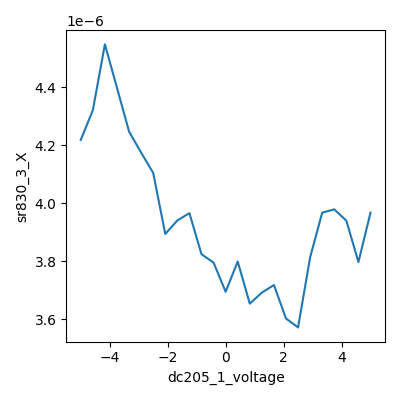

2026-06-23 20:43:47,516 [INFO] Completed in 0h 0m 32s
2026-06-23 20:43:47,517 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\30\data.tsv.gz
heater 5.0 V -> Probe1 T 320.9 mK, curr 4.626e-04 A
2026-06-23 20:45:05,481 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:45:07,023 [INFO] Starting sweep with ID 31
2026-06-23 20:45:07,024 [INFO] Minimum duration 0h 0m 25s


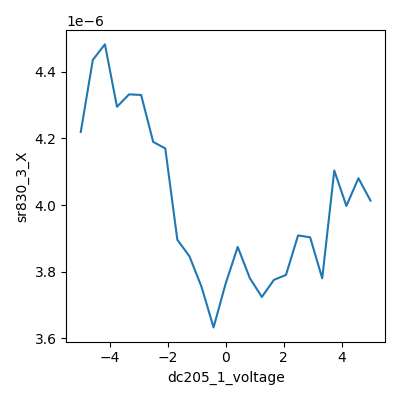

2026-06-23 20:45:39,472 [INFO] Completed in 0h 0m 32s
2026-06-23 20:45:39,472 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\31\data.tsv.gz
heater 4.75 V -> Probe1 T 309.7 mK, curr 4.273e-04 A
2026-06-23 20:46:57,410 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:46:58,912 [INFO] Starting sweep with ID 32
2026-06-23 20:46:58,913 [INFO] Minimum duration 0h 0m 25s


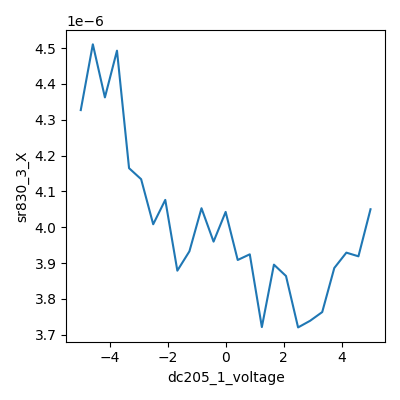

2026-06-23 20:47:31,109 [INFO] Completed in 0h 0m 31s
2026-06-23 20:47:31,110 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\32\data.tsv.gz
heater 4.5 V -> Probe1 T 294.2 mK, curr 3.930e-04 A
2026-06-23 20:48:49,050 [INFO] Ramping dc205_1_voltage: 0.0 -> -5.0
2026-06-23 20:48:50,554 [INFO] Starting sweep with ID 33
2026-06-23 20:48:50,554 [INFO] Minimum duration 0h 0m 25s


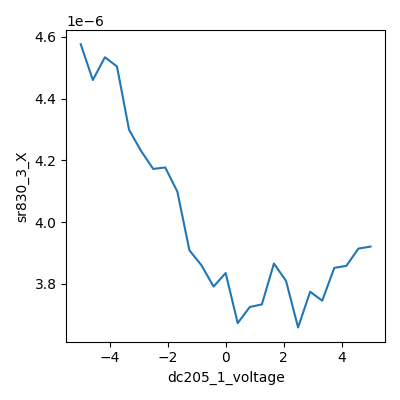

2026-06-23 20:49:22,786 [INFO] Completed in 0h 0m 31s
2026-06-23 20:49:22,787 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\33\data.tsv.gz
Tc collapse ladder done; heater OFF -> recool. T now: 289.02 mK


In [29]:
# === Tc collapse: high-T cooling ladder (warm to 5.5V above Tc, step DOWN). real T=Probe1 ===
import os, time as _t
_lf = r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"
assert _t.time() - os.path.getmtime(_lf) < 120, "Probe1 logfile stale — thermometry worker down"
print(f"start: Probe1 T {temperature()*1e3:.1f} mK, heater {heater.volt()} V, curr {heater.curr():.2e} A")
assert abs(magnet.field()) < 5e-3, "magnet not ~0"

VTG_OP, VBG_OP = -5.39, +4.00
Vdc = np.linspace(-5.0, 5.0, 25)
ladder = [5.5, 5.25, 5.0, 4.75, 4.5]      # warm to 5.5V (above Tc), step DOWN through the collapse
sr830_1.amplitude(0.1); sr830_3.sensitivity(20e-6); k_tg.nplci(1); k_bg.nplci(1)

def heater_to(v_target):
    v0 = float(heater.volt())
    if abs(v_target - v0) < 1e-6: return
    d = np.sign(v_target - v0); v = v0
    while abs(v - v_target) > 1e-6:
        dv = d*min(1.0, abs(v_target - v)); v = round(v+dv, 4)
        heater.volt(v); _t.sleep(1)
        assert abs(heater.curr()) > 1e-9 or v == 0.0, f"heater ~0 A at {v} V — open line"
        _t.sleep(5*60*abs(dv)/1.0)        # 5 min per 1 V

k_tg.volt(VTG_OP); k_bg.volt(VBG_OP)
for hv in ladder:
    heater_to(hv)
    Tnow = float(temperature()); cur = heater.curr()
    print(f"heater {hv} V -> Probe1 T {Tnow*1e3:.1f} mK, curr {cur:.3e} A")
    meas_config["comment"] = f"Tc collapse: heater {hv}V, T~{Tnow*1e3:.1f}mK, Idc+/-50nA, opt, B~0 (cooling)"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('temperature-dependence')
    s.add_comment(f'Tc collapse rung (cooling): heater {hv}V T~{Tnow*1e3:.1f}mK (Probe1); Idc+/-50nA; opt; B~0')
    s.ramp(dc205_1.volt, Vdc[0])
    s.fp(temperature); s.fp(magnet.field); s.fp(heater.volt); s.fp(heater.curr)
    s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(dc205_1.volt)
    for lia in (sr830_1, sr830_2, sr830_3):
        s.fp(lia.X).fp(lia.P)
    s.plot(dc205_1.volt, sr830_3.X)
    s.sweep(dc205_1.volt, Vdc, delay=1)
    dc205_1.volt(0)

heater.volt(0); k_tg.volt(0); k_bg.volt(0)
print("Tc collapse ladder done; heater OFF -> recool. T now:", temperature()*1e3, "mK")


## HERA — Heater settle calibration: UP ladder (0→6 V, 1 V steps)

New task: calibrate the fridge thermal settle vs heater voltage. This is the data the rig card says to "derive from this session's own ramps" — now possible with Probe1 live. **Up ladder first** (reverse ladder next, to test up/down asymmetry).

**Method:** for each 1 V up-step (0→1, 1→2, 2→3, 3→4, 4→5, 5→6) — ramp the heater (qcodes 5 mV sub-steps), then **record T(t) on Probe1 for ~8 min** (100 pts @ 5 s) while held, one run per step. Each step starts from the *equilibrated* previous level, so the settle is clean. Recorded: `temperature` (Probe1, the measurement), `fridge_temperature` (second sensor, cross-check), `heater.volt`/`heater.curr` (confirms the step drew current). Live plot is `time` vs `temperature` — watch it plateau.

**Discipline / safety:** tops out at **6 V** (sustained ceiling is 6.5 V; validator 0–6.5). Starts from a stable base (asserts heater=0 and T<60 mK — if the sample is still cooling from the T-dependence, wait before running). **Heater is left HELD at 6 V at the end** (equilibrated) so the reverse ladder can step straight down — park it (heater.volt(0)) if you pause for long. ~50 min (6 × ~8 min); interrupt anytime, partial traces are readable. I'll extract the settle time per step (time to reach the plateau / dT/dt below threshold) and we compare against the down ladder for asymmetry.


start: heater 0.0 V, Probe1 T 33.9 mK, fridge 0.0 mK
2026-06-23 21:23:47,876 [INFO] Starting sweep with ID 34
2026-06-23 21:23:47,876 [INFO] Minimum duration 0h 8m 20s


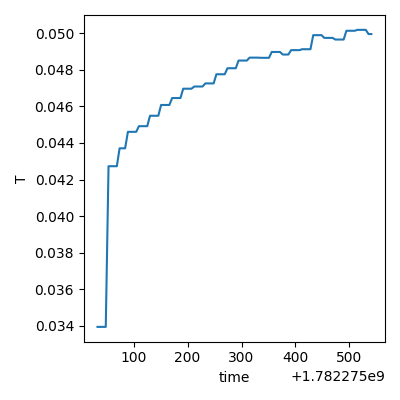

2026-06-23 21:32:21,219 [INFO] Completed in 0h 8m 32s
2026-06-23 21:32:21,220 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\34\data.tsv.gz
  ->1 V: settled-window T 50 mK, heater.curr 4.223e-05 A
2026-06-23 21:32:23,585 [INFO] Starting sweep with ID 35
2026-06-23 21:32:23,586 [INFO] Minimum duration 0h 8m 20s


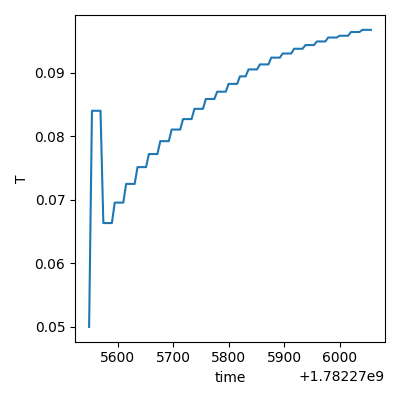

2026-06-23 21:40:56,889 [INFO] Completed in 0h 8m 32s
2026-06-23 21:40:56,890 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\35\data.tsv.gz
  ->2 V: settled-window T 97 mK, heater.curr 1.152e-04 A
2026-06-23 21:40:59,239 [INFO] Starting sweep with ID 36
2026-06-23 21:40:59,240 [INFO] Minimum duration 0h 8m 20s


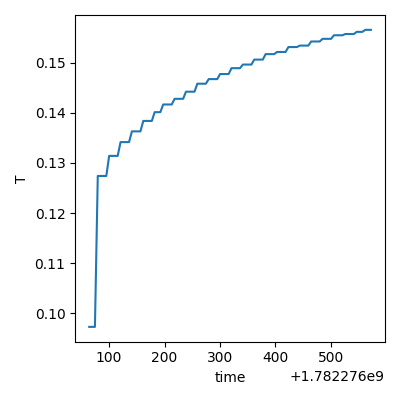

2026-06-23 21:49:32,483 [INFO] Completed in 0h 8m 32s
2026-06-23 21:49:32,484 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\36\data.tsv.gz
  ->3 V: settled-window T 157 mK, heater.curr 2.105e-04 A
2026-06-23 21:49:34,818 [INFO] Starting sweep with ID 37
2026-06-23 21:49:34,819 [INFO] Minimum duration 0h 8m 20s


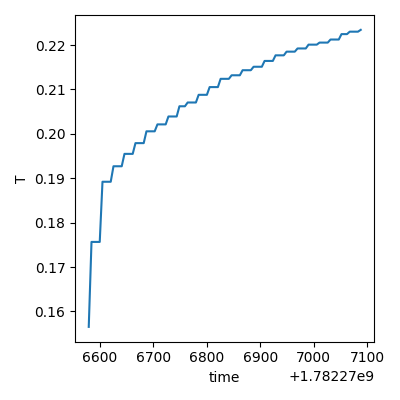

2026-06-23 21:58:08,113 [INFO] Completed in 0h 8m 32s
2026-06-23 21:58:08,114 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\37\data.tsv.gz
  ->4 V: settled-window T 223 mK, heater.curr 3.255e-04 A
2026-06-23 21:58:10,474 [INFO] Starting sweep with ID 38
2026-06-23 21:58:10,474 [INFO] Minimum duration 0h 8m 20s


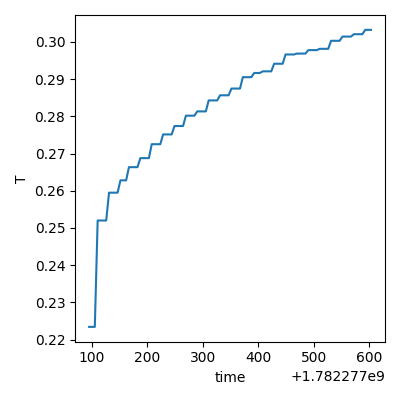

2026-06-23 22:06:43,796 [INFO] Completed in 0h 8m 32s
2026-06-23 22:06:43,797 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\38\data.tsv.gz
  ->5 V: settled-window T 303 mK, heater.curr 4.591e-04 A
2026-06-23 22:06:46,142 [INFO] Starting sweep with ID 39
2026-06-23 22:06:46,143 [INFO] Minimum duration 0h 8m 20s


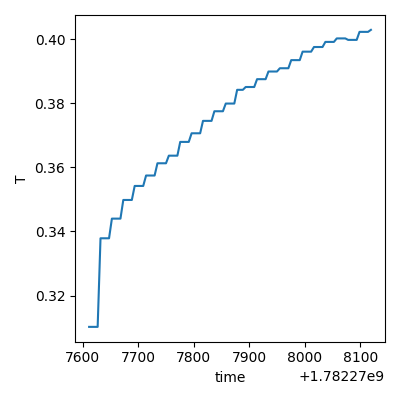

2026-06-23 22:15:19,542 [INFO] Completed in 0h 8m 33s
2026-06-23 22:15:19,542 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\39\data.tsv.gz
  ->6 V: settled-window T 403 mK, heater.curr 6.128e-04 A
UP ladder done. Heater HELD at 6 V (equilibrated) for the reverse ladder. Park heater.volt(0) if pausing.


In [30]:
# === Heater settle calibration — UP ladder (0->6 V, 1 V steps). Record T(t) per step. ===
import os, time as _t
_lf = r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"
assert _t.time() - os.path.getmtime(_lf) < 120, "Probe1 logfile stale — thermometry worker down"
_T0 = float(temperature())
print(f"start: heater {heater.volt()} V, Probe1 T {_T0*1e3:.1f} mK, fridge {fridge_temperature()*1e3:.1f} mK")
assert heater.volt() == 0, "heater must start at 0 V for the 0->1 step"
assert _T0 < 0.060, "sample not at stable base (still cooling?) — wait before the 0->1 step"

N, delay = 100, 5                 # ~8.3 min per step at 5 s resolution
ladder = [1, 2, 3, 4, 5, 6]       # 0->1, 1->2, ..., 5->6 (UP)

for target in ladder:
    heater.volt(float(target))    # the 1 V UP step (qcodes sub-steps at 5 mV; blocks until at target)
    _t.sleep(1)
    cur = heater.curr()
    assert abs(cur) > 1e-9, f"heater drawing ~0 A at {target} V — open line"
    meas_config["comment"] = f"heater-settle UP {target-1}->{target}V, T(t) {delay}s x{N}"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('heater-settle-calibration')
    s.add_comment(f'UP step {target-1}->{target}V; record T(t) {delay}s x{N}; Probe1')
    s.fp(temperature); s.fp(fridge_temperature); s.fp(heater.volt); s.fp(heater.curr)
    s.plot('time', temperature)
    # hold k_tg at 0 (where it is) and record T(t) while the fridge settles after the step
    s.sweep(k_tg.volt, np.full(N, 0.0), delay=delay)
    print(f"  ->{target} V: settled-window T {temperature()*1e3:.0f} mK, heater.curr {cur:.3e} A")

print("UP ladder done. Heater HELD at 6 V (equilibrated) for the reverse ladder. Park heater.volt(0) if pausing.")


## HERA — Heater settle calibration: DOWN ladder (6→0 V) + asymmetry test

Up-ladder result (settle = time for |dT/dt| < 2 mK/min, Probe1):
0→1 V **~1.9 min** · 1→2 V **~6.8 min** · 2→3 V **~6.6 min** · 3→4 V **~7.8 min** · 4→5 V **>7.2 min** · 5→6 V **>8.3 min** (top two outran the 8.3-min window — slow tail). Settle grows strongly with heater level.

**Reverse ladder** to test up/down asymmetry: step the heater **down** 6→5, 5→4, …, 1→0 V, recording T(t) per step until it settles. Two changes from the up-ladder: **(1) longer window — 12.5 min/step** (150 pts @ 5 s) so the slow tails are actually captured this time (the up-ladder's high-V steps were truncated); (2) start from the held 6 V. **Note:** 6 V was still settling when the up-ladder ended (T ~388 mK climbing toward the card's ~423 mK), so the 6→5 step starts from a not-fully-equilibrated 6 V — fine for measuring the *cooling* settle dynamics, just flagged. The down-steps are **cooling** moves (fridge cooling power does the work) — they may settle faster or slower than heating; that difference is the asymmetry.

**Cost ~75 min** (6 × 12.5 min) — longer than the up-ladder because of the slow-tail discovery; interrupt anytime, partial traces are readable. Ends with heater parked at 0 V (cooling to base). I'll extract each down-settle with the same dT/dt criterion and put up-vs-down side by side at each voltage level. The 1–4 V steps compare cleanly both ways; at 5–6 V the up-values are lower bounds (window-limited), so the down-values there are actual-vs-lower-bound.


In [ ]:
# === Heater settle calibration — DOWN ladder (6->0 V). 12.5 min/step window. ===
import os, time as _t
_lf = r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"
assert _t.time() - os.path.getmtime(_lf) < 120, "Probe1 logfile stale — thermometry worker down"
print(f"start: heater {heater.volt()} V, Probe1 T {temperature()*1e3:.1f} mK (note: 6 V may still be settling)")
assert abs(heater.volt() - 6.0) < 0.01, "expected heater held at 6 V from the up-ladder"

N, delay = 150, 5                 # 12.5 min per step at 5 s resolution
ladder = [5, 4, 3, 2, 1, 0]       # 6->5, 5->4, ..., 1->0 (DOWN)

for target in ladder:
    heater.volt(float(target))    # the 1 V DOWN step
    _t.sleep(1)
    cur = heater.curr()
    print(f"step ->{target} V: heater.curr {cur:.3e} A")
    meas_config["comment"] = f"heater-settle DOWN {target+1}->{target}V, T(t) {delay}s x{N}"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('heater-settle-calibration')
    s.add_comment(f'DOWN step {target+1}->{target}V; record T(t) {delay}s x{N}; Probe1')
    s.fp(temperature); s.fp(fridge_temperature); s.fp(heater.volt); s.fp(heater.curr)
    s.plot('time', temperature)
    s.sweep(k_tg.volt, np.full(N, 0.0), delay=delay)
    print(f"  ->{target} V done: T {temperature()*1e3:.0f} mK")

print("DOWN ladder done. Heater at 0 V (parked) -> cooling to base.")


## HERA — DO NOT run cell 74. First: does it actually settle? (fixed-6 V hold)

You're right — my back-to-back ladder never waited for each step to settle before the next, so the high-V "settle times" are confounded by accumulated drift (run 37→4 V ended still rising 2.6 mK/min, run 38→5 V at 3.2 mK/min — each high step started on a drifting baseline). And live Probe1 shows 6 V is **still climbing ~5 mK/min ~20 min after the step** — not settled.

**This cell isolates one level:** heater **held at 6 V (no step)**, record T(t) until it plateaus — to answer "does it settle at all, and by when," cleanly. Watch the live `time` vs `temperature` plot; **interrupt when it's visibly flat** (or it runs ~30 min). If T plateaus → the fridge does settle, just slowly (real settle time); if it keeps drifting indefinitely → something else is going on (base drift / heat leak), which changes the whole picture.

**Then I redo the calibration properly:** apply a step → **wait until |dT/dt| < ~1 mK/min (genuinely settled)** → only then the next step. That gives clean per-step settle-vs-V (and a fair up/down asymmetry test). **Skip cell 74** (it has the same back-to-back flaw, just a longer window). Run this (cell 76) instead.


heater 6.0 V held (no step); T now 409.3 mK, fridge 0.0 mK
2026-06-23 22:20:44,665 [INFO] Starting sweep with ID 40
2026-06-23 22:20:44,666 [INFO] Minimum duration 0h 30m 0s


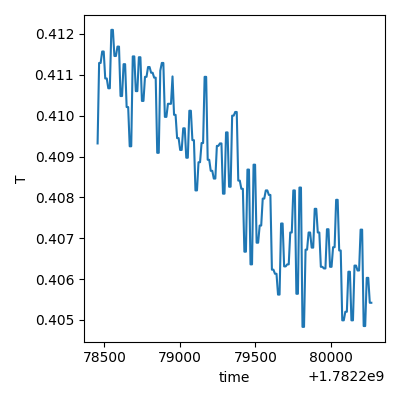

2026-06-23 22:51:08,330 [INFO] Completed in 0h 30m 23s
2026-06-23 22:51:08,331 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260623-zf1\data\40\data.tsv.gz
done. T now 405.42 mK


In [31]:
# === Does it settle? Hold heater at 6 V (NO step), record T(t) until it plateaus. ===
import os, time as _t
_lf = r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"
assert _t.time() - os.path.getmtime(_lf) < 120, "Probe1 logfile stale — thermometry worker down"
assert abs(heater.volt() - 6.0) < 0.01, "expected heater held at 6 V"
print(f"heater {heater.volt()} V held (no step); T now {temperature()*1e3:.1f} mK, fridge {fridge_temperature()*1e3:.1f} mK")

meas_config["comment"] = "heater-settle FIXED-6V hold: does T plateau? (no step, ~30 min, interrupt when flat)"
s = sweep.AsyncStation(meas_config)
s.add_comment('heater-settle-calibration')
s.add_comment('FIXED 6V hold settle test; NO step; record T(t) until plateau')
s.fp(temperature); s.fp(fridge_temperature); s.fp(heater.volt); s.fp(heater.curr)
s.plot('time', temperature)
s.sweep(k_tg.volt, np.full(180, 0.0), delay=10)   # ~30 min; interrupt when the live plot is flat
print("done. T now", temperature()*1e3, "mK")


## HERA — Reverse ladder, DONE RIGHT: adaptive down-ladder (6→0 V, settle-verified)

Corrected method (per your point): each down-step **waits for genuine settle** before the next. Starting from the clean settled 6 V (~405 mK, confirmed flat in run 40). For each step 6→5, 5→4, …, 1→0 V: apply the step, then record T(t) and **break only when |dT/dt| < 1 mK/min, sustained ≥90 s** (true plateau) — or a 35 min/step safety cap. So every down-settle is clean and starts from a settled baseline, and we get a real down-settle-vs-V to compare against a (re-done, equally-clean) up-ladder for the asymmetry.

**Down-steps are cooling moves** (the fridge's cooling power does the work) — they may settle faster or slower than heating; that's the asymmetry. Each step's full T(t) trace + extracted settle time is saved to `hera_scratch/settle_down_<V>.npz`; the cell prints the settle time per step live (watch the `time` vs `temperature` plot too). **~1–1.5 h total** (adaptive — fast steps finish quickly, slow ones take their time); interrupt anytime, each completed step is already saved. Ends with the heater parked at 0 V (cooling to base). I'll read the traces and put up-vs-down side by side once it's done (or as steps land if I check in).


In [32]:
# === Adaptive DOWN ladder (6->0 V): each step waits for genuine settle. ===
import os
SCR = r"C:\Users\toploader\measurements\aaron\20260623-zf1\hera_scratch"
LF  = r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"
assert time.time() - os.path.getmtime(LF) < 120, "Probe1 logfile stale — thermometry worker down"
assert abs(heater.volt() - 6.0) < 0.01, "expected settled 6 V start (run 40)"
print(f"start: heater {heater.volt()} V, T {temperature()*1e3:.1f} mK (settled 6 V baseline)")

def step_settle(target, max_min=35, samp=20, thresh=1.0, sustain=90, win=150, t_min=180):
    """Step heater to target, record T(t), return when |dT/dt|<thresh mK/min sustained."""
    heater.volt(float(target))                      # the down-step (sub-stepped, blocks until there)
    t0 = time.time(); ts = []; Ts = []; settle_t = None; below = None
    while (time.time() - t0) < max_min*60:
        now = time.time() - t0; T = float(temperature())*1e3
        ts.append(now); Ts.append(T)
        if len(ts) >= 6:
            tw = np.array(ts); Tw = np.array(Ts); m = tw > now - win
            if m.sum() >= 4:
                slope = abs(np.polyfit(tw[m], Tw[m], 1)[0]*60)   # mK/min
                if slope < thresh:
                    if below is None: below = now
                    elif (now - below) >= sustain and now > t_min:
                        settle_t = below; break
                else:
                    below = None
        time.sleep(samp)
    np.savez(os.path.join(SCR, f"settle_down_{int(target)}.npz"),
             t=np.array(ts), T=np.array(Ts),
             settle_t=(settle_t if settle_t is not None else -1.0), target=float(target))
    msg = f"settled {settle_t:.0f}s ({settle_t/60:.1f} min)" if settle_t is not None else f"NOT settled in {max_min} min"
    print(f"  ->{target} V: T {Ts[0]:.0f}->{Ts[-1]:.0f} mK ; {msg}")
    return settle_t

for tgt in [5, 4, 3, 2, 1, 0]:
    print(f"step ->{tgt} V ...")
    step_settle(tgt)

print(f"DOWN ladder done. heater {heater.volt()} V (parked) ; T {temperature()*1e3:.1f} mK")


start: heater 6.0 V, T 405.6 mK (settled 6 V baseline)
step ->5 V ...
  ->5 V: T 406->307 mK ; settled 840s (14.0 min)
step ->4 V ...
  ->4 V: T 307->228 mK ; settled 780s (13.0 min)
step ->3 V ...
  ->3 V: T 228->163 mK ; settled 780s (13.0 min)
step ->2 V ...
  ->2 V: T 163->105 mK ; settled 780s (13.0 min)
step ->1 V ...
  ->1 V: T 105->56 mK ; settled 880s (14.7 min)
step ->0 V ...
  ->0 V: T 56->36 mK ; settled 480s (8.0 min)
DOWN ladder done. heater 0.0 V (parked) ; T 35.7 mK


## HERA — (optional) clean adaptive UP ladder, to make the asymmetry rigorous

We're parked at base (35.7 mK, heater 0 V) — the right start for a clean up-ladder that mirrors the down one. Same method: step 0→1, 1→2, …, 5→6 V, each **waiting for |dT/dt|<1 mK/min sustained** before the next, so the heating settles are clean (unlike my first back-to-back attempt). Then I plot **settle vs ΔT for UP and DOWN on the same axes** for a rigorous asymmetry comparison (heating-power-limited vs cooling-power-limited), controlling for the fact that the V→T levels aren't equally spaced.

**This is optional** — the asymmetry is already indicated (up ~2–7 min vs down ~13–15 min; cooling slower). Run cell 81 if you want the rigorous matched comparison (~1–1.5 h, adaptive, traces saved to `settle_up2_<V>.npz`); otherwise we can call the calibration here with the down-ladder + the asymmetry direction established. Heater ends parked at 6 V (settled) — I'd then park it to 0, or leave for follow-up.


In [ ]:
# === (optional) Adaptive UP ladder (0->6 V): clean, settle-verified. Mirrors the down ladder. ===
import os
SCR = r"C:\Users\toploader\measurements\aaron\20260623-zf1\hera_scratch"
LF  = r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"
assert time.time() - os.path.getmtime(LF) < 120, "Probe1 logfile stale"
assert heater.volt() == 0, "expected heater at 0 V (base) start"
assert temperature() < 0.060, "not at stable base yet"
print(f"start: heater {heater.volt()} V, T {temperature()*1e3:.1f} mK (base)")

def step_settle(target, max_min=35, samp=20, thresh=1.0, sustain=90, win=150, t_min=180):
    heater.volt(float(target))
    t0 = time.time(); ts=[]; Ts=[]; settle_t=None; below=None
    while (time.time()-t0) < max_min*60:
        now=time.time()-t0; T=float(temperature())*1e3
        ts.append(now); Ts.append(T)
        if len(ts)>=6:
            tw=np.array(ts); Tw=np.array(Ts); m=tw>now-win
            if m.sum()>=4:
                sl=abs(np.polyfit(tw[m],Tw[m],1)[0]*60)
                if sl<thresh:
                    if below is None: below=now
                    elif (now-below)>=sustain and now>t_min: settle_t=below; break
                else: below=None
        time.sleep(samp)
    np.savez(os.path.join(SCR, f"settle_up2_{int(target)}.npz"),
             t=np.array(ts), T=np.array(Ts), settle_t=(settle_t if settle_t is not None else -1.0), target=float(target))
    print(f"  ->{target} V: T {Ts[0]:.0f}->{Ts[-1]:.0f} mK ; " +
          (f"settled {settle_t:.0f}s ({settle_t/60:.1f} min)" if settle_t is not None else f"NOT settled in {max_min} min"))

for tgt in [1,2,3,4,5,6]:
    print(f"step ->{tgt} V ...")
    step_settle(tgt)
print(f"UP ladder done. heater {heater.volt()} V (held at 6 V, settled). T {temperature()*1e3:.1f} mK")
